# Google Maps: từ/cụm từ nào gắn với đánh giá điểm thấp?

**Câu hỏi kế thừa từ `eda._present.ipynb`:** Trong review địa điểm ăn uống, từ/cụm từ 1–3 gram nào liên hệ với nhóm điểm thấp, và liên hệ đó có ổn định khi chia dữ liệu hay chỉ do câu lặp/một vài quán?

**Nguồn trực tiếp:** [Google Maps JSON](../data/raw/ggmap/gmap.json), [notebook Foody mẫu](eda._present.ipynb), [Foody JSON dùng trong notebook mẫu](../data/processed/18-10-2026.json). Mọi số liệu/nhận xét dưới đây dựa vào output liền trước; không dùng số liệu bên ngoài. Dữ liệu nguồn được giữ nguyên.

**Giả định và quy tắc suy luận:** phân tích mô tả để đặt giả thuyết, sau đó kiểm chứng liên hệ bằng tập validation tách theo nhóm. Định nghĩa điểm thấp của Google Maps là **1–2/5**: phép quy đổi tuyến tính `rating / scale ≤ 0.5` tương ứng `0 < rating ≤ 5/10` bên Foody. Đây là giả định về ngưỡng số học, không chứng minh hai thang đo có cùng ý nghĩa tâm lý. Khảo sát thêm ngưỡng ≤3/5 ở phần độ nhạy. Rating không phải nhãn cảm xúc do người gán.

**Cách đọc:** mỗi phần trình bày mục đích/lý do → code và kết quả → markdown diễn giải, giới hạn và bước kế tiếp. Khoảng một phần ba nội dung diễn giải dành cho phản biện, kiểm tra giả định và cách xác minh. `Run All` thực thi toàn bộ quy trình, gồm tính lại Foody để đối chiếu công bằng.

## 1. Đọc dữ liệu và kiểm tra các trường quyết định phân tích

**Mục đích:** xác định đơn vị quan sát, thang điểm, mức thiếu dữ liệu và ý nghĩa các cờ có sẵn. **Vì sao:** khóa trùng của Foody dùng ngày đăng và thiết bị; áp dụng máy móc khi Maps thiếu các trường này có thể loại nhầm review. Chưa dùng `weak_sentiment`, `training_eligible` hay `duplicate_of` làm chân lý; trước hết đối chiếu chúng với nội dung và rating.

In [1]:
from pathlib import Path
import json, re, gc, hashlib, platform, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupShuffleSplit
import sklearn
%matplotlib inline
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 115,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', 160)
SEED = 42
TOKEN_PATTERN = r'(?u)\b\w+\b'
TOKEN_RE = re.compile(TOKEN_PATTERN)
roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p/'data/raw/ggmap/gmap.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong thư mục dự án có data/raw/ggmap/gmap.json.')
GMAP_PATH = ROOT/'data/raw/ggmap/gmap.json'
FOODY_PATH = ROOT/'data/processed/18-10-2026.json'
TEMPLATE_PATH = ROOT/'notebooks/eda._present.ipynb'

def normalize_text(series):
    return (series.astype('string').fillna('').str.normalize('NFC').str.lower()
            .str.replace(r'\s+', ' ', regex=True).str.strip())

def fingerprint(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

with GMAP_PATH.open(encoding='utf-8') as f:
    gmap_raw = pd.DataFrame(json.load(f))
assert {'rating','rating_scale','text_clean','restaurant_id','review_id'} <= set(gmap_raw.columns)
g = gmap_raw.copy(deep=True)
g['rating_num'] = pd.to_numeric(g['rating'], errors='coerce')
g['text_norm'] = normalize_text(g['text_clean'])
g['n_tokens'] = g['text_norm'].map(lambda t: len(TOKEN_RE.findall(t)))
g['n_chars'] = g['text_norm'].str.len()
g['valid_rating'] = g['rating_num'].isin([1,2,3,4,5]) & g['rating_scale'].eq(5)
print(f'Dữ liệu: {g.shape[0]:,} review, {gmap_raw.shape[1]} cột, {g.restaurant_id.nunique():,} địa điểm.')
print('Python', platform.python_version(), '| pandas',pd.__version__, '| sklearn',sklearn.__version__)
print('SHA256 gmap.json:', fingerprint(GMAP_PATH))
audit = pd.Series({
    'Tổng review': len(g), 'Rating thiếu': g['rating'].isna().sum(),
    'Rating có giá trị nhưng không hợp lệ': (g['rating'].notna() & ~g['valid_rating']).sum(),
    'Text clean rỗng': g['text_norm'].eq('').sum(),
    'Không có token (gồm text rỗng)': g['n_tokens'].eq(0).sum(),
    'Review ID trùng dư': g['review_id'].duplicated().sum(),
    'Native review ID trùng dư': g['native_review_id'].dropna().duplicated().sum(),
    'Có duplicate_of': g['duplicate_of'].notna().sum(),
    'training_eligible=False': (~g['training_eligible']).sum(),
    'published_at thiếu': g['published_at'].isna().sum(),
    'device thiếu': g['device'].isna().sum(),
    'city thiếu': g['city'].isna().sum(),
},name='Số review').to_frame()
audit['Tỷ lệ (%)'] = audit['Số review']/len(g)*100
display(audit.round(3))
flag_counts = Counter(flag for flags in g['quality_flags'] for flag in flags)
display(pd.Series(flag_counts,name='Review có cờ').sort_values(ascending=False).to_frame())
display(pd.crosstab(g['rating_num'].fillna('Thiếu'), g['weak_sentiment'].fillna('Thiếu')))
print('language_hint:',g.language_hint.value_counts().to_dict())
print('rating_scale:',g.rating_scale.value_counts().to_dict())
print('split:',g['split'].value_counts().to_dict())
# Kiểm tra liên kết duplicate_of thay vì tự động xóa mọi cờ near-duplicate.
linked = g.loc[g['duplicate_of'].notna(), ['review_id','duplicate_of','restaurant_id','rating_num','text_norm']].copy()
linked = linked.merge(g[['review_id','restaurant_id','rating_num','text_norm']],
                      left_on='duplicate_of',right_on='review_id',suffixes=('','_target'),how='left',validate='many_to_one')
linked['same_shop'] = linked.restaurant_id.eq(linked.restaurant_id_target)
linked['same_rating'] = linked.rating_num.eq(linked.rating_num_target)
linked['same_text'] = linked.text_norm.eq(linked.text_norm_target)
print('Kiểm tra duplicate_of:')
display(linked[['same_shop','same_rating','same_text']].value_counts().rename('Số liên kết').to_frame())
print('Liên kết không tìm thấy đích:',int(linked.review_id_target.isna().sum()))

Dữ liệu: 147,565 review, 37 cột, 1,925 địa điểm.
Python 3.12.14 | pandas 2.3.3 | sklearn 1.9.1


SHA256 gmap.json: 41bf02e9a65867aead620c0c8373f28b4fc1806ae687ed50de91df526f65265e


,Số review,Tỷ lệ (%)
Tổng review,147565,100.000
Rating thiếu,1010,0.684
Rating có giá trị nhưng không hợp lệ,0,0.000
Text clean rỗng,15535,10.528
Không có token (gồm text rỗng),15617,10.583
Review ID trùng dư,0,0.000
Native review ID trùng dư,0,0.000
Có duplicate_of,60,0.041
training_eligible=False,15608,10.577
published_at thiếu,147565,100.000


,Review có cờ
near_duplicate_candidate_limit,19153
city_unknown,17447
no_text_signal,15548
empty_or_placeholder_text,15535
edited_time_not_publication,5464
missing_or_invalid_rating,1010
exact_text_duplicate,148
near_text_duplicate,57
text_normalized_or_redacted,30


weak_sentiment,Thiếu,negative,neutral,positive
rating_num,,,,
1.0,0,14784,0,0
2.0,0,4777,0,0
3.0,0,0,11096,0
4.0,0,0,0,26042
5.0,0,0,0,89856
Thiếu,1010,0,0,0


language_hint: {'vi': 130443, 'und': 17122}
rating_scale: {5: 147565}
split: {'train': 115261, 'test': 18738, 'validation': 13566}


Kiểm tra duplicate_of:


Số liên kết
same_shop same_rating same_text             
True      True        True                54
          False       True                 6

Liên kết không tìm thấy đích: 0


### Kết quả kiểm tra đầu vào và phản biện

147.565 review thuộc 1.925 địa điểm; 10,53% text rỗng, 0,68% thiếu rating, và 100% thiếu `published_at`/`device`. Do đó cần phân biệt **review có điểm** với **review có văn bản để tìm keyword**; không dùng thời gian tương đối để suy diễn xu hướng năm/tháng. Có 17.447 dòng thiếu city nên không tự suy city từ tên quán.

`weak_sentiment` trùng hoàn toàn với các nhóm rating quan sát được (1–2 → negative, 3 → neutral, 4–5 → positive). Vì vậy dùng trường này để “xác nhận cảm xúc” sẽ chỉ lặp lại nhãn điểm, không phải kiểm chứng độc lập. `language_hint=und` cũng không tự chứng minh đó là tiếng nước ngoài.

**Kiểm tra ngược:** review/native ID đều duy nhất. Trong 60 `duplicate_of`, có 54 cặp cùng quán, điểm và text; 6 cặp cùng text nhưng khác điểm. Bước tiếp theo chỉ loại 54 bản sao ứng viên đồng nhất này theo chính sách làm việc; giữ 6 trường hợp khác điểm. Không thể chứng minh mọi cặp đồng nhất là cùng một trải nghiệm vì thiếu người viết/thời gian. Sẽ báo tác động giữ lại chúng để kiểm tra độ nhạy.

## 2. Tạo tập phân tích và đo tác động của việc loại review không có văn bản

**Mục đích:** xây dựng mẫu số nhất quán cho mọi phép đếm. **Vì sao:** kiểm tra trước cho thấy hơn 15 nghìn nội dung rỗng, nên chỉ nhìn phân phối rating trên toàn bộ JSON có thể mô tả sai tập dùng cho keyword. Không lọc trực tiếp theo `training_eligible`; tự xác định điều kiện từ điểm, token và chính sách trùng đã nêu để tránh loại không rõ lý do.

,Bước,Số review,Loại tại bước
0,Dữ liệu gốc,147565,0
1,Sau loại bản sao ứng viên đồng nhất,147511,54
2,Thêm điều kiện rating 1–5 hợp lệ,146501,1010
3,Thêm điều kiện text không rỗng,130966,15535
4,Thêm điều kiện có ít nhất 1 token,130884,82


Working nhưng training_eligible=False: 6
training_eligible=True nhưng không vào working: 1079


,raw_reviews,text_reviews,Có text/token (%),working_reviews
rating_num,,,,
1.0,14784,13861,93.76,13858
2.0,4777,4360,91.27,4360
3.0,11096,9424,84.93,9424
4.0,26042,22958,88.16,22956
5.0,89856,80335,89.40,80286


LOW_BASELINES {"raw_valid": 0.13347207533008085, "working": 0.13919195623605635, "working_n": 130884, "working_low_n": 18218, "shops": 1900}


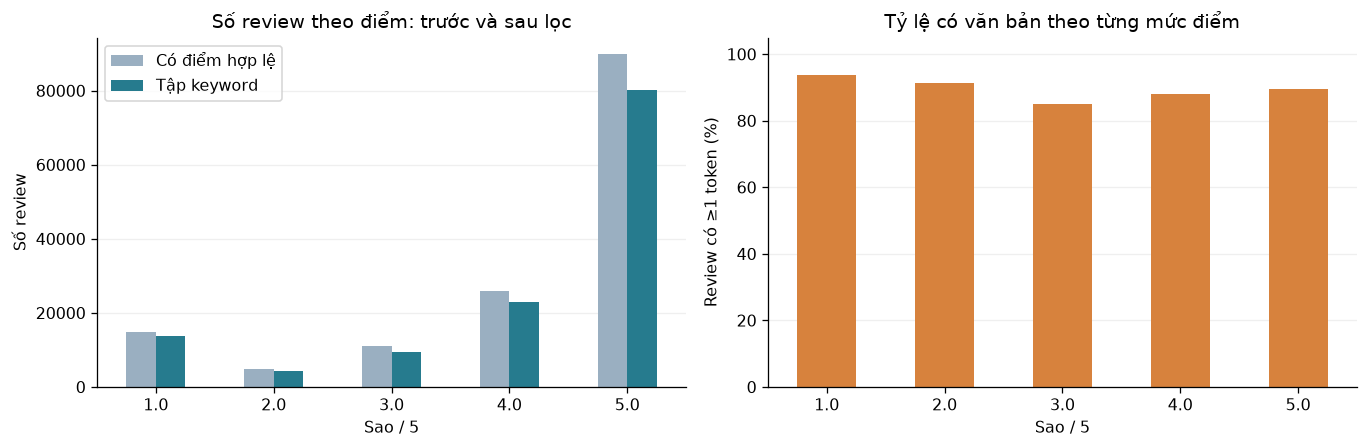

In [2]:
verified_duplicate_ids = set(linked.loc[linked.same_shop & linked.same_rating & linked.same_text, 'review_id'])
remove_dup = g['review_id'].isin(verified_duplicate_ids)
conditions = [
    ('Dữ liệu gốc', pd.Series(True,index=g.index)),
    ('Sau loại bản sao ứng viên đồng nhất', ~remove_dup),
    ('Thêm điều kiện rating 1–5 hợp lệ', ~remove_dup & g.valid_rating),
    ('Thêm điều kiện text không rỗng', ~remove_dup & g.valid_rating & g.text_norm.ne('')),
    ('Thêm điều kiện có ít nhất 1 token', ~remove_dup & g.valid_rating & g.n_tokens.gt(0)),
]
flow = pd.DataFrame([{'Bước':name,'Số review':int(mask.sum())} for name,mask in conditions])
flow['Loại tại bước'] = -flow['Số review'].diff().fillna(0).astype(int)
display(flow)
working = g.loc[conditions[-1][1]].copy().reset_index(drop=True)
working['shop_id'] = working.restaurant_id
working['is_low'] = working.rating_num.le(2)
assert working.review_id.is_unique and working.n_tokens.gt(0).all() and working.valid_rating.all()
assert len(working) == int(conditions[-1][1].sum())
assert working.is_low.nunique()==2
print('Working nhưng training_eligible=False:',int((~working.training_eligible).sum()))
print('training_eligible=True nhưng không vào working:',int((g.training_eligible & ~conditions[-1][1]).sum()))
raw_valid = g.loc[g.valid_rating]
coverage = raw_valid.groupby('rating_num').agg(raw_reviews=('review_id','size'),
                                              text_reviews=('n_tokens',lambda s:int(s.gt(0).sum())))
coverage['Có text/token (%)'] = 100*coverage.text_reviews/coverage.raw_reviews
coverage['working_reviews'] = working.rating_num.value_counts()
coverage['working_reviews'] = coverage.working_reviews.fillna(0).astype(int)
display(coverage.round(2))
print('LOW_BASELINES',json.dumps({'raw_valid':float(raw_valid.rating_num.le(2).mean()),
                                'working':float(working.is_low.mean()),
                                'working_n':len(working),'working_low_n':int(working.is_low.sum()),
                                'shops':int(working.shop_id.nunique())}))
fig, axes = plt.subplots(1,2,figsize=(12,4))
coverage[['raw_reviews','working_reviews']].rename(columns={'raw_reviews':'Có điểm hợp lệ','working_reviews':'Tập keyword'}).plot.bar(ax=axes[0],color=['#9aafc1','#267b8e'],rot=0)
axes[0].set(title='Số review theo điểm: trước và sau lọc',xlabel='Sao / 5',ylabel='Số review')
coverage['Có text/token (%)'].plot.bar(ax=axes[1],color='#d7823d',rot=0)
axes[1].set(title='Tỷ lệ có văn bản theo từng mức điểm',xlabel='Sao / 5',ylabel='Review có ≥1 token (%)',ylim=(0,105))
for ax in axes: ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### Ta biết gì sau bước lọc?

Tập keyword còn **130.884 review tại 1.900 địa điểm**, gồm **18.218 review 1–2 sao (13,919%)**. Các bước loại lần lượt 54 bản sao ứng viên, 1.010 dòng thiếu điểm, 15.535 text rỗng và 82 text không rỗng nhưng không có token. Nhóm 1 sao có văn bản đạt 93,76%, còn 3 sao chỉ 84,93%; việc lọc text làm baseline thấp tăng từ 13,347% trên review có điểm lên 13,919% trong working. Vì thế mọi lift sau đây phải dùng baseline của chính tập đang xét.

**Vòng phản biện:** 6 dòng trong working có `training_eligible=False`, và 1.079 dòng được gắn `True` vẫn không đạt điều kiện của notebook. Điều này cho thấy cờ có sẵn không thay thế được định nghĩa tập phân tích. Tỷ lệ điểm thấp ở working cũng không phải ước lượng không chệch cho toàn bộ khách hàng: các review có/không có text khác nhau theo rating. Có thể xác minh bằng bảng coverage và lưu đồ phía trên; phần độ nhạy sẽ kiểm tra quyết định loại bản sao.

## 3. Độ dài, câu lặp và phạm vi địa lý trước khi chọn keyword

**Mục đích:** kiểm tra khối lượng xử lý và nguồn bằng chứng. **Vì sao:** khảo sát đầu vào cho thấy nhiều review rất ngắn và những câu như “ngon”, “được rồi”, “tốt” lặp nhiều lần. Ta đếm **số review chứa cụm** thay vì tổng số lần cụm được nhắc; nhóm cùng text phải nằm cùng phía khi chia discovery/validation. Token regex chỉ là đơn vị chữ/số, chưa phải từ đã tách đúng ngữ nghĩa tiếng Việt.

,n_tokens,n_chars
count,130884.00,130884.0
mean,39.71,175.39
std,53.01,235.25
min,1.00,1.0
50%,23.00,101.0
90%,90.00,399.0
95%,132.00,580.0
99%,261.00,1159.0
max,960.00,4093.0


,reviews,median_tokens,mean_tokens,p95_tokens,short_le5_pct
is_low,,,,,
3–5 sao,112666,21.0,36.56,120.0,10.18
1–2 sao,18218,37.0,59.23,190.0,6.14


,Lượt cụm trước binary
1-gram,5197835
2-gram,5066951
3-gram,4937883


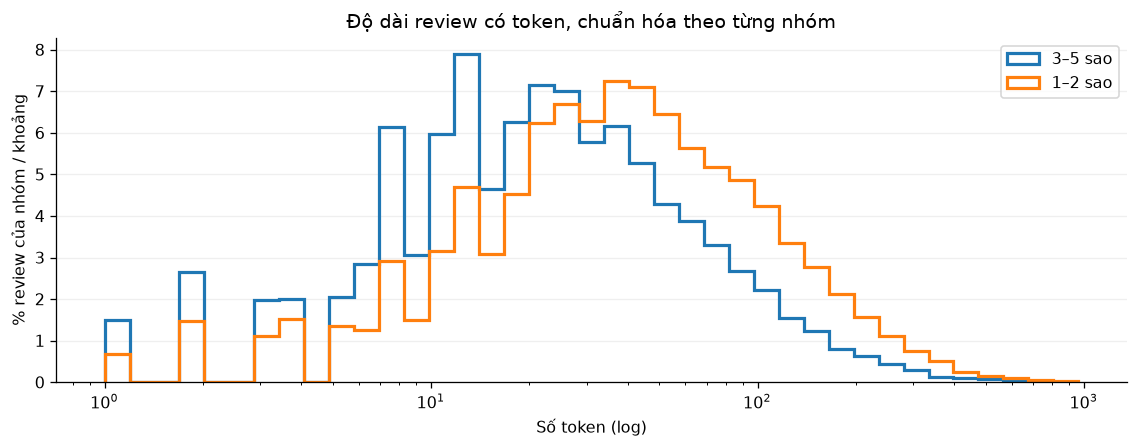

In [3]:
length_summary = working[['n_tokens','n_chars']].describe(percentiles=[.5,.9,.95,.99]).round(2)
display(length_summary)
length_by_group = working.groupby('is_low').agg(reviews=('review_id','size'),median_tokens=('n_tokens','median'),
    mean_tokens=('n_tokens','mean'),p95_tokens=('n_tokens',lambda s:s.quantile(.95)),
    short_le5_pct=('n_tokens',lambda s:100*s.le(5).mean()))
display(length_by_group.rename(index={True:'1–2 sao',False:'3–5 sao'}).round(2))
volume = pd.Series({f'{n}-gram':int((working.n_tokens-n+1).clip(lower=0).sum()) for n in [1,2,3]},name='Lượt cụm trước binary')
display(volume.to_frame())
fig, ax = plt.subplots(figsize=(10,4))
bins=np.geomspace(1,working.n_tokens.max()+1,40)
for label,part in working.groupby('is_low'):
    # Trọng số mỗi nhóm cộng thành 100%; giúp so hai nhóm có kích thước khác nhau.
    ax.hist(part.n_tokens,bins=bins,weights=np.full(len(part),100/len(part)),histtype='step',linewidth=2,
            label='1–2 sao' if label else '3–5 sao')
ax.set_xscale('log'); ax.set(title='Độ dài review có token, chuẩn hóa theo từng nhóm',xlabel='Số token (log)',ylabel='% review của nhóm / khoảng')
ax.legend(); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()

### Thông tin và insight về độ dài

Google Maps có trung vị **23 token**, P95 **132**, lớn nhất **960**; số lượt 1–3 gram trước binary khoảng **15,20 triệu**. Nhóm 1–2 sao có trung vị **37 token**, P95 **190**, cao hơn nhóm 3–5 sao (**21**, **120**). Review ≤5 token chiếm 6,14% nhóm thấp và 10,18% nhóm còn lại. Histogram chuẩn hóa theo từng nhóm cho thấy khác biệt này không chỉ do kích thước hai nhóm khác nhau.

**Vòng phản biện:** text dài tạo nhiều cơ hội xuất hiện cụm, nên lift cao có thể đi cùng độ dài chứ chưa là đặc trưng cảm xúc riêng. Binary chỉ loại việc lặp cùng cụm trong một review, không loại được nhiễu do độ dài. Tiếp theo cần kiểm tra số text/quán đóng góp, và phân tầng độ dài cho các cụm tiêu biểu. Token ở đây là chữ/số theo regex; “phục vụ” gồm 2 token, không phải một đơn vị từ vựng đã được tách từ.

### 3.1. Nội dung lặp và mức tập trung địa điểm

**Mục đích:** xác định câu lặp có gắn với nhiều mức điểm/quán và quan sát thành phần mẫu. **Vì sao:** một câu xuất hiện hàng trăm lần không tương đương hàng trăm cách diễn đạt độc lập; độ phủ quán và số text khác nhau cần đi kèm lift. City thiếu được hiển thị riêng, không thay bằng `search_area` vì vùng tìm kiếm không tự chứng minh địa chỉ.

In [4]:
repeat_groups = working.groupby('text_norm').agg(reviews=('review_id','size'),shops=('shop_id','nunique'),
    rating_levels=('rating_num','nunique'),low_reviews=('is_low','sum')).sort_values('reviews',ascending=False)
repeated_mask = working.text_norm.duplicated(keep=False)
print('REPEAT_SUMMARY',{'unique_text':int(working.text_norm.nunique()),'repeat_groups':int(repeat_groups.reviews.gt(1).sum()),
                       'repeat_rows':int(repeated_mask.sum()),'repeat_pct':float(100*repeated_mask.mean())})
display(repeat_groups.head(12))
city_summary = working.assign(city_display=working.city.fillna('Chưa xác định')).groupby('city_display').agg(
    reviews=('review_id','size'),shops=('shop_id','nunique'),low_rate=('is_low','mean'))
city_summary['review_share_pct']=100*city_summary.reviews/len(working)
city_summary['low_rate_pct']=100*city_summary.pop('low_rate')
display(city_summary.sort_values('reviews',ascending=False).round(2))
shop_counts=working.shop_id.value_counts()
print(f'Top 10 địa điểm đóng góp {shop_counts.head(10).sum()/len(working):.2%} review; địa điểm nhiều nhất có {shop_counts.max():,} review.')
print('Các split có sẵn có địa điểm chồng lấn:')
print(working.groupby('shop_id')['split'].nunique().value_counts().to_dict())

REPEAT_SUMMARY {'unique_text': 124688, 'repeat_groups': 1084, 'repeat_rows': 7280, 'repeat_pct': 5.562177195073501}


,reviews,shops,rating_levels,low_reviews
text_norm,,,,
ngon,541,310,5,4
được rồi,431,282,5,15
tốt,407,284,5,9
tuyệt vời,226,186,3,0
đồ ăn ngon,161,126,4,1
đẹp,93,72,4,1
cafe ngon,83,64,4,3
"đồ ăn ngon, nhân viên nhiệt tình",79,61,1,0
rất tốt,77,64,3,0


,reviews,shops,review_share_pct,low_rate_pct
city_display,,,,
Hồ Chí Minh,56923,655,43.49,12.34
Hà Nội,42350,658,32.36,15.22
Quy Nhơn,18372,307,14.04,14.36
Chưa xác định,13239,280,10.12,15.92


Top 10 địa điểm đóng góp 0.77% review; địa điểm nhiều nhất có 101 review.
Các split có sẵn có địa điểm chồng lấn:
{1: 1900}


### Nội dung lặp cho ta biết gì?

Có **124.688 text khác nhau**, 1.084 nhóm text lặp và **7.280 review thuộc nhóm lặp (5,56%)**. “Ngon” có 541 review/310 quán nhưng chỉ 4 review thấp; “tốt” có 407 review/284 quán, 9 review thấp. Cùng text có thể đi kèm đủ 5 mức sao, nên câu chữ không xác định duy nhất điểm. Không xóa các câu phổ biến chỉ vì giống nội dung; sẽ nhóm chúng khi chia discovery/validation.

Hồ Chí Minh và Hà Nội đóng góp 43,49% và 32,36% working; city chưa xác định chiếm 10,12%. Top 10 địa điểm chỉ chiếm 0,77% review; max 101 review/địa điểm gợi ý cần kiểm tra giới hạn thu thập, nhưng riêng số max chưa đủ chứng minh có cap 100/101. Các split có sẵn không chồng quán trong working.

**Vòng phản biện:** số quán phân tán không đồng nghĩa mẫu đại diện. Tỷ lệ thấp theo city còn chịu tác động thành phần địa điểm và cách lấy mẫu. Các cờ near-duplicate/candidate-limit cho thấy chưa thể khẳng định đã loại hết câu gần giống; chia theo exact text chỉ ngăn rò rỉ nguyên câu, không ngăn mọi paraphrase.

## 4. Đọc mẫu để kiểm tra cách hiểu điểm và văn bản

**Mục đích:** xem rating có thể bao gồm nội dung khen/chê hỗn hợp và các token lỗi hay không. **Vì sao:** bảng `weak_sentiment` chỉ phản ánh rating; cần đọc câu thật để tránh gán cảm xúc chỉ từ một chữ. Mỗi nhóm lấy mẫu cố định seed 42; đây là kiểm tra định tính, không dùng để ước lượng tỷ lệ cảm xúc toàn dữ liệu.

In [5]:
for name,mask in [('A. Nhóm 1–2 sao',working.is_low),('B. Nhóm 3 sao',working.rating_num.eq(3)),
                  ('C. Nhóm 4–5 sao',working.rating_num.ge(4))]:
    print('\n'+name)
    with pd.option_context('display.max_colwidth',None):
        display(working.loc[mask,['review_id','restaurant_name','rating_num','n_tokens','text_clean']].sample(n=3,random_state=SEED))
print('\nD. Có text nhưng regex không tạo token (đã loại khỏi keyword)')
with pd.option_context('display.max_colwidth',None):
    display(g.loc[g.text_norm.ne('') & g.n_tokens.eq(0),['review_id','rating_num','text_clean']].head(5))
print('\nE. Thiếu rating nhưng có nội dung (không tự suy rating từ text)')
with pd.option_context('display.max_colwidth',200):
    display(g.loc[~g.valid_rating & g.n_tokens.gt(0),['review_id','rating','text_clean']].head(3))


A. Nhóm 1–2 sao


,review_id,restaurant_name,rating_num,n_tokens,text_clean
108222,gmap:d3bfd208241cac761dc1e6e6d8c36f08,Nhà Hàng Gà Mạnh Hoạch Hoàng Cầu,2.0,6,Phục vụ đồ ăn quá chậm
128122,gmap:fa8b83321e4084bc9676e5f1e9adabb9,Quán Bờm,1.0,60,"Chưa bao giờ thấy trải nghiệm tệ như vậy. Khuyên mọi người cân nhắc trước khi ăn. Đồ ăn order rất lâu luôn, thái độ nvien thì cực kém. Hôm ấy mình đi nvien thì chửi um lên với ông chú ship hàng thậm chí văng tục và thách thức đánh nhau. Đồ ăn thì không ổn tí nào cả ."
85133,gmap:a68c3238ab28ea52373d38575109f55a,Phở Hùng Bình Thạnh,1.0,1,dở



B. Nhóm 3 sao


,review_id,restaurant_name,rating_num,n_tokens,text_clean
112307,gmap:dbb3dbb9559e0848976976beb09f6bd6,Chợ Đêm Quy Nhơn,3.0,14,"Hơi chán, chỉ có bán quần áo giày dép linh tinh. Ít đặc biệt"
33939,gmap:41f612c62dc11631b0dcab6480f64279,Nhà Hàng Hải Sản Rạn Biển 1,3.0,17,Đồ ăn ngon và tươi sống. Vị trí đi lại thuận tiện và giá khá đắt đỏ.
87012,gmap:aa3202a49506ad394ab2b721163d6cbb,Nhà Hàng Hải Sản Liên Thành,3.0,3,Ngon bổ rẻ



C. Nhóm 4–5 sao


,review_id,restaurant_name,rating_num,n_tokens,text_clean
80699,gmap:9dc51737c0f4cca9a64d7591d5a64af0,NHÀ HÀNG BUFFET HẢI SẢN ALIBABA,5.0,56,"Buffet hải sản ăn thả ga mà giá rẻ lắm. Đi ăn cũng ổn hải sadn thì tùy loại cũng cod loại tươi loại hơi ốp/cát. Có món bếp làm gìum thì nêm nếm khá ngon. Gợi ý mấy bạn ăn ốc hương rang muối, hàu mỡ hành, cua sốt trứng muối từ bếp nhen."
76619,gmap:95c009676704048d4731ef0c2e8d5aba,Ga Kafe,4.0,66,"Không gian rộng rãi, khu vực ngoài sân yên tĩnh phù hợp để ngồi học bài và làm việc. Nhân viên thân thiện, để ý tới các yêu cầu riêng của khách hàng. Nhân viên mèo thích làm quen vui đùa với khách hàng (trừ mèo khác) Đồ uống ổn, ly bạc sỉu của mình đậm vị cà phê. Có thể xin thêm đá nếu cần."
125330,gmap:f5233f777a28fd36335c339b2aa9feea,Day Maker Coffee Bean,5.0,25,"Day Maker Coffee là một quán cafe đáng ghé thăm, đáp ứng được tất cả những gì mà một người yêu thích cà phê cần."



D. Có text nhưng regex không tạo token (đã loại khỏi keyword)


,review_id,rating_num,text_clean
1416,gmap:0262f9d644c52fc9341df351cca6de09,5.0,💯
6118,gmap:0a5b2b00ac940a4fc1417e42483794b7,5.0,🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤🤤
7149,gmap:0c1a23a90a92e87e3f20fc20fe60a900,5.0,❤️❤️❤️
8353,gmap:0e1cfe3f541a3a55460d2c414f5606f1,4.0,👍👍
12188,gmap:14b0b7474e31c15238ff85fe31784d5a,4.0,☺️😊



E. Thiếu rating nhưng có nội dung (không tự suy rating từ text)


,review_id,rating,text_clean
14,gmap:0005561e14a8b0bd2daf724ac24f1385,NaN,"Khách sạn rất tuyệt vời, một trải nghiệm hài lòng khi lưu trú tại đây"
132,gmap:003d245c6e12a724a84026d87ced5754,NaN,"Vị trí rất đẹp, mặt tiền đường Nguyễn Thị Minh Khai, gần công viên Tao Đàn, mình hẹn bạn ở đó uống nước Matcha và ăn biítteak, matcha ngon nhất mình từng uống. Bạn mình cũng khen đồ ăn ngon. Quán ..."
157,gmap:00461b9eba26a622a87ab616449b50f4,NaN,"Vị trí tốt, nhân viên thân thiện, đồ uống ngon."


### Đọc mẫu giúp điều chỉnh cách hiểu nào?

Mẫu 1–2 sao có lời phàn nàn rõ về phục vụ chậm, thái độ và món ăn; một mẫu chỉ có một token “dở”. Ở 3 sao có cả “Hơi chán…”, đánh giá vừa khen đồ ăn vừa chê giá, và “Ngon bổ rẻ”. Mẫu 5 sao về buffet cũng có nhận xét một số hải sản không tươi/ốp. Vì thế **nhóm điểm thấp không tương đương nhãn cảm xúc nhị phân**, và 3 sao cần được kiểm tra như một lựa chọn ngưỡng riêng.

Các trường hợp 0 token được đọc có emoji như 💯, ❤️, 👍: bị loại do phương pháp n-gram này không biểu diễn được chúng, không phải vì chúng không có ý nghĩa. Mẫu thiếu rating vẫn có văn bản khen; không tự điền điểm bằng suy đoán từ text. Có cả mẫu chợ đêm và nội dung lưu trú, nên phạm vi thực tế rộng hơn nhà hàng thuần túy.

**Vòng phản biện:** vài mẫu không cho biết tỷ lệ khen/chê toàn tập hoặc chứng minh mọi rating thiếu/emoji đều giống các ví dụ. Có thể xác minh bằng đọc lại `review_id` đã hiển thị và mở rộng một mẫu phân tầng có gán nhãn thủ công. Bước keyword sẽ kiểm chứng liên hệ thống kê, không dùng những mẫu này làm ground truth.

## 5. Khám phá n-gram và kiểm tra ổn định bằng 5 lần chia theo text

**Mục đích:** trả lời trực tiếp câu hỏi bằng các cụm có liên hệ lặp lại trên validation. **Vì sao:** 1–2 sao chỉ chiếm 13,92% và có text dài hơn, nên số lần xuất hiện thô không đủ để đánh giá từ khóa. Bước này giữ phương pháp chính của notebook mẫu để có cơ sở đối chiếu.

Mỗi lần chia dùng `GroupShuffleSplit(seed=42, n_splits=5)`, dành 20% **nhóm text** cho validation; cùng text không xuất hiện hai phía. Từ điển 1–3 gram chỉ học từ review thấp của discovery; mỗi cụm cần ≥5 review thấp. Mỗi cụm được tính tối đa một lần/review (`binary=True`).

\[
\mathrm{lift}(k)=\frac{P(\mathrm{low}\mid k)}{P(\mathrm{low})}
=\frac{n_{\mathrm{low},k}/n_k}{n_{\mathrm{low}}/N}.
\]

Chọn trên discovery khi lift ≥2. Validation đủ mẫu nếu có ≥10 review chứa cụm. “Ổn định theo ngưỡng” nghĩa là được chọn ≥4/5 lần, đủ mẫu ≥3 lần, và ≥80% lần đủ mẫu có lift ≥2. Không gán lift=0 khi support=0; không chọn một lần chia đẹp nhất. Min–max lift không phải khoảng tin cậy, các lần chia không độc lập.

**Phạm vi kiểm chứng:** sử dụng toàn bộ tập làm việc cho EDA, kể cả các split có sẵn. Các nhãn `train/test/validation` trong JSON không được coi là tập kiểm định mù trong notebook này. Nếu dùng dữ liệu cho mô hình sau EDA, cần một holdout mới chưa xem để đánh giá cuối cùng. Việc chia theo text chưa kiểm tra khái quát sang quán mới; sẽ kiểm tra riêng ở phần sau.

In [6]:
MIN_LOW_SUPPORT = 5
MIN_LIFT = 2.0
MIN_VALID_SUPPORT = 10
BATCH_SIZE = 5000
N_SPLITS = 5

def count_support(vectorizer, texts):
    counts=np.zeros(len(vectorizer.vocabulary_),dtype=np.int64)
    for start in range(0,len(texts),BATCH_SIZE):
        matrix=vectorizer.transform(texts.iloc[start:start+BATCH_SIZE])
        counts+=np.asarray(matrix.sum(axis=0)).ravel()
    return counts

def discover_validate(data, disc_pos, val_pos, split_id, purge_shared_text=False):
    disc=data.iloc[disc_pos]
    val=data.iloc[val_pos]
    before=len(val)
    if purge_shared_text:
        val=val.loc[~val.text_norm.isin(set(disc.text_norm))]
    assert not (set(disc.text_norm)&set(val.text_norm))
    if disc.is_low.nunique()<2 or val.is_low.nunique()<2:
        raise ValueError('Discovery/validation phải có cả hai nhóm điểm.')
    vec=CountVectorizer(token_pattern=TOKEN_PATTERN,ngram_range=(1,3),lowercase=False,
                        binary=True,min_df=MIN_LOW_SUPPORT,dtype=np.int32)
    low_matrix=vec.fit_transform(disc.loc[disc.is_low,'text_norm'])
    low_disc=np.asarray(low_matrix.sum(axis=0)).ravel()
    del low_matrix
    support_disc=count_support(vec,disc.text_norm)
    lift_disc=(low_disc/support_disc)/disc.is_low.mean()
    selected=lift_disc>=MIN_LIFT
    names=vec.get_feature_names_out()
    # Chỉ đếm vocabulary đã chọn cho validation để giảm chi phí bộ nhớ.
    chosen=names[selected]
    if len(chosen):
        val_vec=CountVectorizer(vocabulary={k:i for i,k in enumerate(chosen)},
            token_pattern=TOKEN_PATTERN,ngram_range=(1,3),lowercase=False,binary=True,dtype=np.int32)
        val_vec._validate_vocabulary()
        support_val=count_support(val_vec,val.text_norm)
        low_val=count_support(val_vec,val.loc[val.is_low,'text_norm'])
        p=np.divide(low_val,support_val,out=np.full(len(chosen),np.nan),where=support_val>0)
        run=pd.DataFrame({'split':split_id,'keyword':chosen,'support_discovery':support_disc[selected],
            'low_support_discovery':low_disc[selected],'lift_discovery':lift_disc[selected],
            'support_validation':support_val,'low_support_validation':low_val,'lift_validation':p/val.is_low.mean()})
    else:
        run=pd.DataFrame(columns=['split','keyword','support_discovery','low_support_discovery','lift_discovery',
                                 'support_validation','low_support_validation','lift_validation'])
    run['evaluable']=run.support_validation.ge(MIN_VALID_SUPPORT)
    run['positive_validation']=run.lift_validation.ge(MIN_LIFT)
    report={'split':split_id,'discovery_n':len(disc),'validation_n':len(val),
        'purged_validation_n':before-len(val),'discovery_low_pct':100*disc.is_low.mean(),
        'validation_low_pct':100*val.is_low.mean(),'candidates':len(names),'selected':len(run),
        'evaluable':int(run.evaluable.sum())}
    return run,report

def summarize_stability(runs):
    selected=runs.groupby('keyword').agg(n_selected=('split','nunique'),
                                         median_discovery_lift=('lift_discovery','median'))
    validation=(runs.loc[runs.evaluable].groupby('keyword').agg(n_evaluable=('split','nunique'),
        positive_rate=('positive_validation','mean'),median_validation_lift=('lift_validation','median'),
        min_validation_lift=('lift_validation','min'),max_validation_lift=('lift_validation','max')))
    result=selected.join(validation,how='left').reset_index()
    result['n_evaluable']=result.n_evaluable.fillna(0).astype(int)
    result['stable']=(result.n_selected.ge(4)&result.n_evaluable.ge(3)&result.positive_rate.ge(.8))
    result['assessment']=np.select([result.n_evaluable.lt(3),result.stable],
        ['Chưa đủ lần kiểm chứng','Ổn định theo ngưỡng'],default='Chưa ổn định theo ngưỡng')
    return result.sort_values(['stable','n_selected','median_validation_lift'],ascending=False).reset_index(drop=True)

def run_text_stability(data,label):
    splitter=GroupShuffleSplit(n_splits=N_SPLITS,test_size=.2,random_state=SEED)
    runs=[]; reports=[]
    for split_id,(di,vi) in enumerate(splitter.split(data,groups=data.text_norm),1):
        run,report=discover_validate(data,di,vi,split_id)
        runs.append(run); reports.append(report)
        print(label,'split',split_id,':',report['selected'],'chọn;',report['evaluable'],'đủ mẫu validation',flush=True)
    all_runs=pd.concat(runs,ignore_index=True)
    if all_runs.empty: raise ValueError('Không có keyword đạt discovery.')
    return all_runs,summarize_stability(all_runs),pd.DataFrame(reports)

keyword_runs,keyword_stability,split_report=run_text_stability(working,'Google Maps')
display(split_report.round(3))
display(keyword_stability.assessment.value_counts().rename('Số keyword').to_frame())
print('GMAP_STABLE',int(keyword_stability.stable.sum()))

Google Maps split 1 : 31283 chọn; 6167 đủ mẫu validation


Google Maps split 2 : 31116 chọn; 6215 đủ mẫu validation


Google Maps split 3 : 30665 chọn; 6407 đủ mẫu validation


Google Maps split 4 : 31004 chọn; 6237 đủ mẫu validation


Google Maps split 5 : 30765 chọn; 6285 đủ mẫu validation


,split,discovery_n,validation_n,purged_validation_n,discovery_low_pct,validation_low_pct,candidates,selected,evaluable
0,1,105216,25668,0,13.850,14.204,45016,31283,6167
1,2,104827,26057,0,13.964,13.739,44967,31116,6215
2,3,104196,26688,0,13.991,13.639,44426,30665,6407
3,4,104917,25967,0,13.930,13.875,44828,31004,6237
4,5,104999,25885,0,13.805,14.383,44353,30765,6285


,Số keyword
assessment,
Chưa đủ lần kiểm chứng,33816
Ổn định theo ngưỡng,4452
Chưa ổn định theo ngưỡng,1400


GMAP_STABLE 4452


### Thông tin từ 5 lần kiểm chứng

Có **4.452 n-gram ổn định theo tiêu chí**, **33.816 n-gram chưa đủ lần kiểm chứng**, và 1.400 n-gram chưa ổn định theo ngưỡng. Mỗi discovery chọn khoảng 30,7–31,3 nghìn ứng viên, nhưng mỗi validation chỉ khoảng 6,2–6,4 nghìn cụm đủ ≥10 review. Baseline validation dao động 13,639–14,383%; từng lift đã dùng đúng baseline tương ứng.

**Insight:** rất nhiều cụm đạt discovery nhờ support thấp hoặc quá đặc thù, nên không thể lấy tất cả ứng viên discovery làm kết luận. Bước tiếp theo ưu tiên cụm đủ mẫu và kiểm tra nguồn bằng chứng thay vì chỉ sắp xếp lift lớn nhất.

**Vòng phản biện:** 4.452 là số đặc trưng, không phải số vấn đề độc lập; các n-gram chồng lấn có thể xuất phát từ cùng câu. Các lần chia dùng lại dữ liệu, không có điều chỉnh đa kiểm định và chưa chứng minh khả năng áp dụng ra ngoài mẫu. “Ổn định” chỉ là nhãn vận hành theo bộ ngưỡng nêu trước.

### 5.1. Ưu tiên cụm đủ mẫu và đo độ phủ bằng chứng

**Mục đích:** chuyển từ danh sách đạt ngưỡng sang các cụm có thể diễn giải. **Vì sao:** lift cao của một mảnh câu hiếm chưa hữu ích. Thống kê toàn tập bên dưới dùng để mô tả và sắp thứ tự trình bày, không thay cho lift validation. Bảng/biểu đồ ưu tiên cụm ≥2 token, ≥100 review toàn tập; đo số quán và số text cho các cụm hiển thị. Đây là lựa chọn cách đọc kết quả, không phải ngưỡng được tối ưu sau khi nhìn validation.

,keyword,support_all,low_support_all,p_low_all,shops,distinct_texts,largest_shop_share_pct,n_selected,n_evaluable,positive_rate,median_validation_lift,min_validation_lift,max_validation_lift
16,tồi tệ,151,145,0.960,135.0,148.0,2.649,5,5,1.0,7.040,6.373,7.128
12,cực kì tệ,135,131,0.970,116.0,135.0,2.963,5,5,1.0,7.040,6.777,7.332
14,kì tệ,135,131,0.970,116.0,135.0,2.963,5,5,1.0,7.040,6.777,7.332
21,thiếu tôn,114,108,0.947,99.0,114.0,2.632,5,5,1.0,7.036,6.499,7.332
22,thiếu tôn trọng,113,107,0.947,98.0,113.0,2.655,5,5,1.0,7.036,6.499,7.332
23,nghiệm quá tệ,128,123,0.961,116.0,127.0,1.562,5,5,1.0,7.028,6.720,7.207
25,coi thường,148,143,0.966,128.0,148.0,2.027,5,5,1.0,6.999,6.879,7.128
28,coi thường khách,102,98,0.961,91.0,102.0,2.941,5,5,1.0,6.962,6.692,7.040
34,thái độ như,129,120,0.930,119.0,129.0,1.550,5,5,1.0,6.953,6.537,7.207
29,1 lời xin,108,102,0.944,101.0,108.0,1.852,5,5,1.0,6.953,5.954,7.332


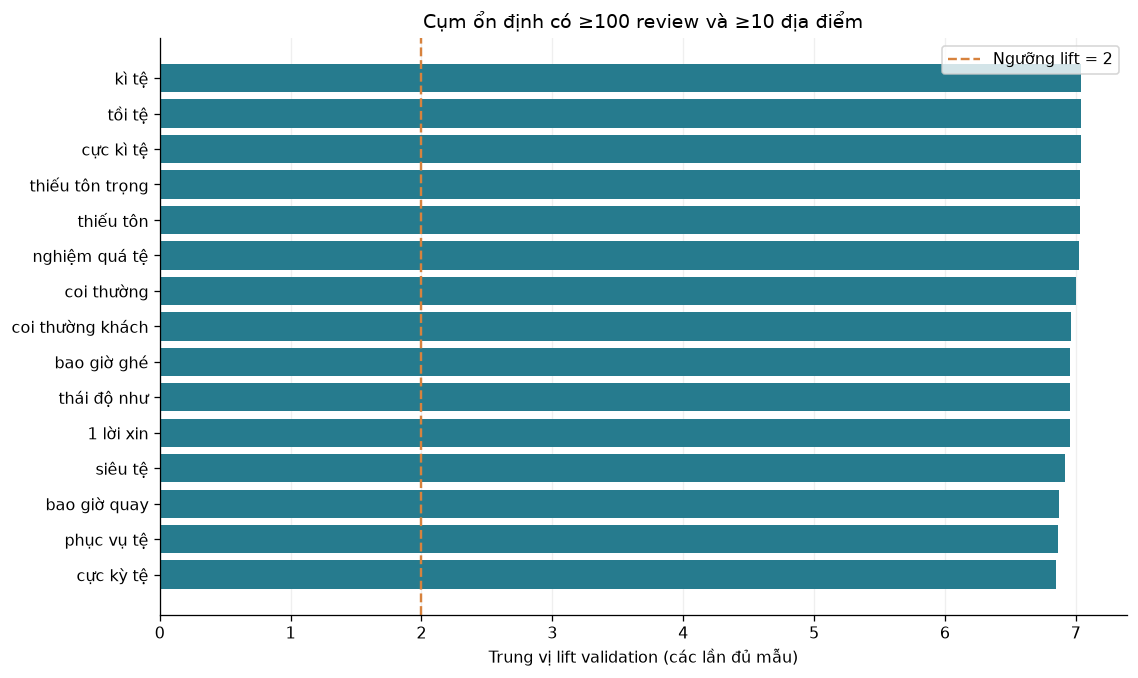

TOP_PHRASES [{"keyword":"tồi tệ","support_all":151,"shops":135.0,"median_validation_lift":7.0400438837},{"keyword":"cực kì tệ","support_all":135,"shops":116.0,"median_validation_lift":7.0400438837},{"keyword":"kì tệ","support_all":135,"shops":116.0,"median_validation_lift":7.0400438837},{"keyword":"thiếu tôn","support_all":114,"shops":99.0,"median_validation_lift":7.0358752328},{"keyword":"thiếu tôn trọng","support_all":113,"shops":98.0,"median_validation_lift":7.0358752328},{"keyword":"nghiệm quá tệ","support_all":128,"shops":116.0,"median_validation_lift":7.0275091505},{"keyword":"coi thường","support_all":148,"shops":128.0,"median_validation_lift":6.9985496347},{"keyword":"coi thường khách","support_all":102,"shops":91.0,"median_validation_lift":6.9620354627},{"keyword":"thái độ như","support_all":129,"shops":119.0,"median_validation_lift":6.952726296},{"keyword":"1 lời xin","support_all":108,"shops":101.0,"median_validation_lift":6.952726296},{"keyword":"bao giờ ghé","support_all":

In [7]:
def full_keyword_stats(data,terms):
    terms=list(dict.fromkeys(terms))
    if not terms:
        return pd.DataFrame(columns=['keyword','support_all','low_support_all','p_low_all','lift_all'])
    vec=CountVectorizer(vocabulary={k:i for i,k in enumerate(terms)},token_pattern=TOKEN_PATTERN,
        ngram_range=(1,3),lowercase=False,binary=True,dtype=np.int32)
    vec._validate_vocabulary()
    support=count_support(vec,data.text_norm)
    low=count_support(vec,data.loc[data.is_low,'text_norm'])
    p=np.divide(low,support,out=np.full(len(terms),np.nan),where=support>0)
    return pd.DataFrame({'keyword':terms,'support_all':support,'low_support_all':low,
                         'p_low_all':p,'lift_all':p/data.is_low.mean()})

stable=keyword_stability.loc[keyword_stability.stable].copy()
stable=stable.merge(full_keyword_stats(working,stable.keyword),on='keyword',how='left',validate='one_to_one')
stable['n_terms']=stable.keyword.str.split().str.len()
phrase_table=(stable.loc[stable.n_terms.ge(2)&stable.support_all.ge(100)]
              .sort_values(['median_validation_lift','support_all'],ascending=False).copy())
# Các cụm đứng đầu theo tiêu chí định trước; số quán/text là kiểm tra thêm về sự tập trung.
preview=phrase_table.head(20).copy()

def keyword_mask(data,term):
    # Dùng cùng tokenizer/ranh giới token như CountVectorizer; tránh khớp chuỗi con.
    pat=re.compile(r'(?<!\w)'+r'\s+'.join(re.escape(t) for t in term.split())+r'(?!\w)')
    # Vectorizer loại dấu câu trước khi ghép n-gram, nên khớp trên chuỗi token tương ứng.
    return data.text_norm.map(lambda t:bool(pat.search(' '.join(TOKEN_RE.findall(t)))))

for idx,row in preview.iterrows():
    part=working.loc[keyword_mask(working,row.keyword)]
    assert len(part)==row.support_all
    preview.loc[idx,'shops']=part.shop_id.nunique()
    preview.loc[idx,'distinct_texts']=part.text_norm.nunique()
    preview.loc[idx,'largest_shop_share_pct']=100*part.shop_id.value_counts().max()/len(part)
cols=['keyword','support_all','low_support_all','p_low_all','shops','distinct_texts','largest_shop_share_pct',
      'n_selected','n_evaluable','positive_rate','median_validation_lift','min_validation_lift','max_validation_lift']
display(preview[cols].round(3))
chart=preview.loc[preview.shops.ge(10)].head(15).sort_values('median_validation_lift')
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(chart.keyword,chart.median_validation_lift,color='#267b8e')
ax.axvline(2,color='#d7823d',linestyle='--',label='Ngưỡng lift = 2')
ax.set(title='Cụm ổn định có ≥100 review và ≥10 địa điểm',xlabel='Trung vị lift validation (các lần đủ mẫu)')
ax.legend(); ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
print('TOP_PHRASES',preview[['keyword','support_all','shops','median_validation_lift']].head(12).to_json(orient='records',force_ascii=False))

### Cụm nào nổi bật và có bằng chứng từ đâu?

“Tồi tệ” xuất hiện trong **151 review**, 145 review thấp, tại **135 quán/148 text khác nhau**; lift validation trung vị khoảng **7,04**. “Thiếu tôn trọng” có **113 review**, 107 thấp, tại **98 quán**; “phục vụ tệ” có **265 review**, 246 thấp, tại **212 quán**. “Bao giờ quay” có **658 review**, 630 thấp, tại **456 quán**. Những cụm này không chỉ đến từ một quán hoặc một câu lặp; chúng gợi ý đọc sâu các chủ đề thái độ, phục vụ và ý định không quay lại.

**Vòng phản biện:** biểu đồ hiển thị các cụm được ưu tiên theo lift, không phải bảng xếp hạng nguyên nhân gây bất mãn. Các cụm như “thiếu tôn”, “kì tệ”, “nghiệm quá tệ” là mảnh/chồng lấn của cụm dài hơn. Lift gần 7 nằm sát trần toán học của baseline khoảng 13,92%, nên chênh lệch nhỏ giữa các thanh không có nghĩa khác biệt thực tế lớn. Cần đọc cả review không thấp có chứa cụm trước khi diễn giải; chỉ khi có nhãn khía cạnh độc lập mới ước lượng được tỷ lệ phàn nàn về từng vấn đề.

## 6. Tính lại Foody từ nguồn để có mốc so sánh nhất quán

**Mục đích:** so hai bộ dữ liệu cho cùng câu hỏi bằng cùng tokenizer, cách đếm và quy tắc lift. **Vì sao:** output lưu trong notebook mẫu chưa đồng nhất: cell lọc trùng báo 132.826 review, các cell độ dài/phân phối sau đó vẫn ghi 138.131 review. Cell keyword cuối còn chưa có output. Vì thế không sao chép số liệu keyword hay nhận xét độ dài từ trạng thái lưu sẵn.

Foody được làm sạch đúng hướng dẫn mẫu: chuẩn hóa text, lọc trùng bằng 6 thành phần (platform, shop, datetime, rating, text, device) khi đầy đủ khóa; giữ dòng thiếu khóa; sau đó chỉ giữ `0 < rating ≤10` và ≥1 token. Nhóm thấp là `rating ≤5`. Google Maps vẫn dùng chính sách 54 bản sao ứng viên đồng nhất vì thiếu khóa tương ứng. Sự khác nhau về chính sách trùng phải được giữ trong diễn giải; không thể giả định hai bộ đã có cùng quy trình lấy mẫu/làm sạch.

In [8]:
if not FOODY_PATH.is_file():
    raise FileNotFoundError(f'Cần dữ liệu Foody tại {FOODY_PATH} để chạy đối chiếu cuối.')
f = pd.read_json(FOODY_PATH,dtype={'source_review_id':'string','shop_id':'string','user_pseudo_id':'string'})
assert f.source_platform.eq('Foody').all()
f['rating_num']=pd.to_numeric(f.rating,errors='coerce')
f['text_norm']=normalize_text(f.comment_text)
f['n_tokens']=f.text_norm.map(lambda t:len(TOKEN_RE.findall(t)))
f['n_chars']=f.text_norm.str.len()
missing_values={'','unknown','none','null','nan','nat','<na>','n/a'}
keys=pd.DataFrame(index=f.index)
for col in ['source_platform','shop_id','comment_datetime','device']:
    values=f[col].astype('string').str.normalize('NFC').str.strip()
    if col=='device': values=values.str.lower()
    keys[col]=values.mask(values.str.lower().isin(missing_values))
keys['rating_num']=f.rating_num
keys['text_norm']=f.text_norm.replace('',pd.NA)
complete_key=keys.notna().all(axis=1)
f_dup=complete_key & keys.duplicated(keep='first')
f_valid=f.rating_num.between(0,10)&f.text_norm.ne('')
f_corpus=f.loc[~f_dup&f_valid]
f_remove=f_corpus.rating_num.eq(0)|f_corpus.n_tokens.eq(0)
foody_working=f_corpus.loc[~f_remove,['review_id','shop_id','rating_num','text_norm','n_tokens','n_chars','city']].copy().reset_index(drop=True)
foody_working['is_low']=foody_working.rating_num.le(5)
assert len(f)==len(f.loc[~f_dup])+int(f_dup.sum())
assert not f_dup.loc[~complete_key].any()
assert foody_working.n_tokens.gt(0).all() & foody_working.rating_num.gt(0).all()
print('SHA256 Foody:',fingerprint(FOODY_PATH))
f_flow=pd.Series({'Foody gốc':len(f),'Thiếu khóa (giữ)':int((~complete_key).sum()),
 'Trùng bị loại':int(f_dup.sum()),'Sau lọc trùng':len(f)-int(f_dup.sum()),
 'Corpus hợp lệ trước loại 0/0 token':len(f_corpus),'Rating 0 trong corpus':int(f_corpus.rating_num.eq(0).sum()),
 '0 token trong corpus':int(f_corpus.n_tokens.eq(0).sum()),
 'Giao rating 0 và 0 token':int((f_corpus.rating_num.eq(0)&f_corpus.n_tokens.eq(0)).sum()),
 'Foody working':len(foody_working),'Foody working low':int(foody_working.is_low.sum())},name='Số review')
display(f_flow.to_frame())

def corpus_metrics(raw,work,scale):
    return {'Review gốc':len(raw),'Review working':len(work),'Quán trong working':work.shop_id.nunique(),
      'Điểm thấp (%)':100*work.is_low.mean(),'Token trung vị':work.n_tokens.median(),
      'Token trung bình':work.n_tokens.mean(),'Token P95':work.n_tokens.quantile(.95),
      'Review ≤5 token (%)':100*work.n_tokens.le(5).mean(),
      'Review thuộc text lặp (%)':100*work.text_norm.duplicated(keep=False).mean(),
      'Max review/địa điểm':work.shop_id.value_counts().max(),
      'Lượt 1–3 gram':sum(int((work.n_tokens-n+1).clip(lower=0).sum()) for n in [1,2,3])}
comparison=pd.DataFrame({'Google Maps':corpus_metrics(g,working,5),'Foody':corpus_metrics(f,foody_working,10)})
display(comparison.round(3))
print('COMPARISON',comparison.to_json(force_ascii=False))

SHA256 Foody: f2da10ee4438642ffc16707755fbc667c3031559fe71c7fc94790472c63cad1a


,Số review
Foody gốc,138131
Thiếu khóa (giữ),0
Trùng bị loại,5305
Sau lọc trùng,132826
Corpus hợp lệ trước loại 0/0 token,132826
Rating 0 trong corpus,40
0 token trong corpus,146
Giao rating 0 và 0 token,0
Foody working,132640
Foody working low,23144


,Google Maps,Foody
Review gốc,1.475650e+05,1.381310e+05
Review working,1.308840e+05,1.326400e+05
Quán trong working,1.900000e+03,5.538000e+03
Điểm thấp (%),1.391900e+01,1.744900e+01
Token trung vị,2.300000e+01,7.000000e+01
Token trung bình,3.971300e+01,8.151700e+01
Token P95,1.320000e+02,1.950000e+02
Review ≤5 token (%),9.617000e+00,6.062000e+00
Review thuộc text lặp (%),5.562000e+00,5.853000e+00
Max review/địa điểm,1.010000e+02,4.610000e+02


COMPARISON {"Google Maps":{"Review gốc":147565.0,"Review working":130884.0,"Quán trong working":1900.0,"Điểm thấp (%)":13.9191956236,"Token trung vị":23.0,"Token trung bình":39.7132957428,"Token P95":132.0,"Review ≤5 token (%)":9.616912686,"Review thuộc text lặp (%)":5.5621771951,"Max review\/địa điểm":101.0,"Lượt 1–3 gram":15202669.0},"Foody":{"Review gốc":138131.0,"Review working":132640.0,"Quán trong working":5538.0,"Điểm thấp (%)":17.4487334138,"Token trung vị":70.0,"Token trung bình":81.5165259349,"Token P95":195.0,"Review ≤5 token (%)":6.0622738239,"Review thuộc text lặp (%)":5.8526839566,"Max review\/địa điểm":461.0,"Lượt 1–3 gram":32040453.0}}


### Mốc Foody đã được tính lại

Foody loại **5.305** dòng theo khóa 6 thành phần, còn 132.826 dòng; tiếp tục loại **40 rating 0** và **146 dòng 0 token**, còn **132.640 review**, trong đó **23.144 thấp (17,449%)**, thuộc **5.538 quán**. Các số này thay cho 137.919 working trong output lưu sẵn của notebook mẫu, vì output đó chưa phản ánh bước lọc trùng trước đó.

Với cùng tokenizer, Foody dài hơn rõ rệt: trung vị **70** so với **23 token**, P95 **195** so với **132**; lượt 1–3 gram khoảng **32,04 triệu** so với **15,20 triệu**. Số review working gần nhau không có nghĩa khối lượng văn bản hoặc cơ hội xuất hiện keyword tương đương. Tỷ lệ review thuộc text lặp sau các bước lọc lần lượt 5,85% và 5,56%.

**Vòng phản biện:** hai nguồn khác thang điểm, số quán và chính sách trùng; các chênh lệch này không thể quy hết cho nền tảng hay hành vi người dùng. Để xác minh, chạy lại cell lọc Foody và đối chiếu f_flow, không dùng output notebook mẫu làm chuẩn số học. Các con số là mô tả của hai file được cấp, không phải kết luận về toàn bộ Google Maps/Foody.

### 6.1. Đối chiếu cùng nội dung và phân phối độ dài giữa hai nguồn

**Mục đích:** kiểm tra liệu khác biệt keyword có thể đi cùng khác biệt cách cho điểm và cách viết review. **Vì sao:** cùng một cụm khen phổ biến vẫn có thể nhận điểm thấp; cần quan sát trực tiếp thay vì cho rằng nhãn điểm là cảm xúc chuẩn. Bảng dưới chỉ xét **toàn bộ text đúng bằng cụm**, không gộp các câu dài có chứa cụm.

,Nguồn,Text đúng bằng,Review,Điểm thấp,% thấp,Số mức điểm
0,Google Maps,ngon,541,4,0.74,5
1,Google Maps,tốt,407,9,2.21,5
2,Google Maps,tuyệt vời,226,0,0.00,3
3,Google Maps,bình thường,62,13,20.97,5
4,Google Maps,không ngon,8,7,87.50,3
5,Google Maps,phục vụ kém,14,11,78.57,3
6,Foody,ngon,482,137,28.42,22
7,Foody,tốt,280,198,70.71,20
8,Foody,tuyệt vời,171,71,41.52,19
9,Foody,bình thường,1,1,100.00,1


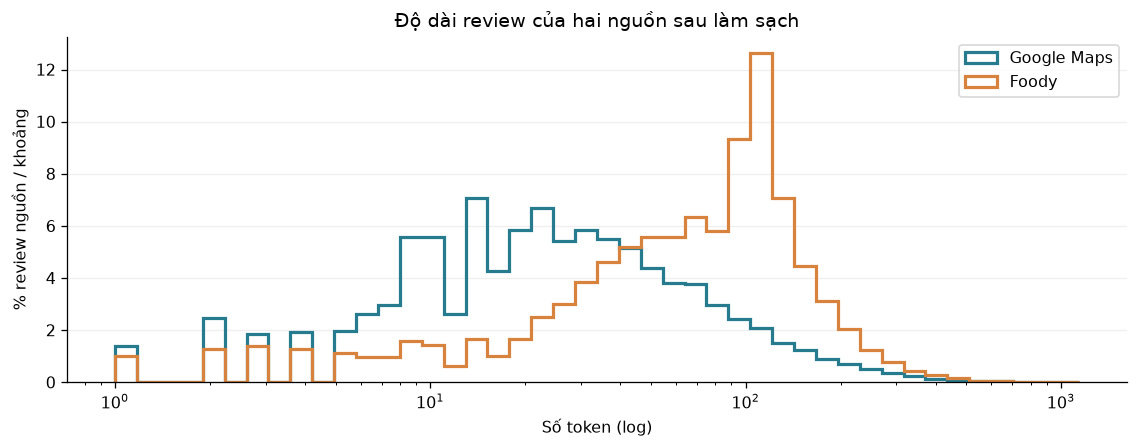

In [9]:
common_rows=[]
for name,data in [('Google Maps',working),('Foody',foody_working)]:
    for text in ['ngon','tốt','tuyệt vời','bình thường','không ngon','phục vụ kém']:
        part=data.loc[data.text_norm.eq(text)]
        common_rows.append({'Nguồn':name,'Text đúng bằng':text,'Review':len(part),'Điểm thấp':int(part.is_low.sum()),
          '% thấp':100*part.is_low.mean() if len(part) else np.nan,'Số mức điểm':part.rating_num.nunique()})
common_text_comparison=pd.DataFrame(common_rows)
display(common_text_comparison.round(2))
fig,ax=plt.subplots(figsize=(10,4))
for name,data,color in [('Google Maps',working,'#267b8e'),('Foody',foody_working,'#d7823d')]:
    ax.hist(data.n_tokens,bins=np.geomspace(1,max(working.n_tokens.max(),foody_working.n_tokens.max())+1,45),
            weights=np.full(len(data),100/len(data)),histtype='step',linewidth=2,label=name,color=color)
ax.set_xscale('log'); ax.set(title='Độ dài review của hai nguồn sau làm sạch',xlabel='Số token (log)',ylabel='% review nguồn / khoảng')
ax.legend(); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()

### Cùng lời khen có cùng mức điểm không?

Với text **đúng bằng** “ngon”, Maps có **4/541 thấp (0,74%)**, Foody **137/482 (28,42%)**. Với “tốt”, hai tỷ lệ là **9/407 (2,21%)** và **198/280 (70,71%)**; “tuyệt vời” là **0/226** và **71/171 (41,52%)**. Đây là khác biệt lớn về liên hệ giữa lời viết và nhãn điểm ngay trong hai file, nên chuyển một danh sách keyword hoặc nhãn rating từ nguồn này sang nguồn kia cần kiểm tra lại.

**Vòng phản biện:** các tỷ lệ dùng hai ngưỡng đã định nghĩa khác thang đo, không tự chứng minh nguồn nào sai hay người dùng cố ý cho điểm lạ. Có thể do cách chấm điểm, lỗi xử lý/ghép dữ liệu hoặc các nguyên nhân khác chưa được xác minh. Bảng này chỉ xét vài text chọn trước; các nhóm “không ngon”/“phục vụ kém” ít mẫu nên không so tỷ lệ như một ước lượng ổn định. Cách kiểm tra trực tiếp là truy vết review ID, rating gốc và trang nguồn của các câu khen nhưng điểm thấp trong Foody.

## 7. Đọc ngữ cảnh của các cụm nổi bật và kiểm tra giả định

**Mục đích:** kiểm tra những cụm liên quan đến thái độ/phục vụ và ý định quay lại có thực sự mô tả trải nghiệm không tốt trong ví dụ cụ thể. **Vì sao:** kết quả n-gram sinh cả mảnh câu như “thiếu tôn”, “nghiệm quá tệ”, “bao giờ quay”; chúng có thể trùng cùng một thông tin và không nên coi là các vấn đề độc lập. Chọn ba cụm từ bảng kết quả để đọc cả mẫu điểm thấp và mẫu điểm cao hơn. Đây là diễn giải sau khám phá, không phải gán nhãn tự động toàn bộ dữ liệu.

In [10]:
context_terms=['thiếu tôn trọng','phục vụ tệ','bao giờ quay']
context_vec=CountVectorizer(vocabulary={k:i for i,k in enumerate(context_terms)},token_pattern=TOKEN_PATTERN,
                          ngram_range=(1,3),binary=True,lowercase=False)
context_matrix=context_vec.fit_transform(working.text_norm)
context_masks={term:np.asarray(context_matrix[:,i].toarray()).ravel().astype(bool) for i,term in enumerate(context_terms)}
for term in context_terms:
    mask=context_masks[term]
    print('\nCụm:',term,'| số review:',int(mask.sum()))
    for label,group in [('Điểm thấp',True),('Điểm cao hơn (kiểm tra ngoại lệ)',False)]:
        part=working.loc[mask & working.is_low.eq(group)]
        print(label,'| N =',len(part))
        if len(part):
            with pd.option_context('display.max_colwidth',None):
                display(part[['review_id','restaurant_name','rating_num','text_clean']].sample(n=1,random_state=SEED))


Cụm: thiếu tôn trọng | số review: 113
Điểm thấp | N = 107


,review_id,restaurant_name,rating_num,text_clean
92213,gmap:b490192f869b53f9bd7c43c7fd601192,Bếp Cô Lý - Món Ngon Miền Trung,1.0,Thái độ và cách hành xử của chủ quán rất rất tệ và thiếu tôn trọng khách. Làm đồ thì quá lâu nhưng không coi khách ra gì


Điểm cao hơn (kiểm tra ngoại lệ) | N = 6


,review_id,restaurant_name,rating_num,text_clean
27875,gmap:365a704b0a0cb7deeae8c3806531ed81,Tranquil Books Coffee,3.0,"Một menu nước với giá từ 60k trở lên. Mình gọi 1 kombucha, 1 trà lá dứa, với serving chỉ bằng 2/3 cốc và 1 nửa là đá như trong ảnh thì mình thấy Tranquil cơ sở Nguyễn Biểu hơi thiếu tôn trọng khách hàng. Mong cửa hàng xem xét lại định lượng đồ uống để khách hàng có trải nghiệm tốt hơn."



Cụm: phục vụ tệ | số review: 265
Điểm thấp | N = 246


,review_id,restaurant_name,rating_num,text_clean
14797,gmap:1c8043cd72ef71162603ee25e97beada,Nhà hàng hải sản Duy Mập,1.0,Nhân viên tầng 3 phục vụ tệ keo vãi. Xin thêm chén nuoc chấm không cho nói het rồi.thùng Đá thì lấy đi cho bàn khác bàn mình toàn nuoc khong co đá. Trải nghiem that âm binh tai day. Giá cao chứ co rẻ dau


... (2 outputs left out)


Cụm: bao giờ quay | số review: 658
Điểm thấp | N = 630


,review_id,restaurant_name,rating_num,text_clean
105118,gmap:cdbfdf790c61d1b632d68e7c8c74719d,Cafe Mậu Dịch,1.0,"Phục vụ mặt như đâm lê, order mặt mũi khó chịu, không nhiệt tình, cách thức phục vụ đúng kiểu khiến khách hàng khó chịu....không bao giờ quay lại lần 2 🙂 …"


Điểm cao hơn (kiểm tra ngoại lệ) | N = 28


,review_id,restaurant_name,rating_num,text_clean
67670,gmap:844797d9156cc57fdfa2cf1ceb48a001,Nhân Sushi-Bito,4.0,"Xưa giờ luôn biết Nhân Sushi là một trong những quán mắc nhất và ngon nhất nên mình rất mong đợi được ăn. Tuy nhiên hôm nay có dịp ăn thì lại vô cùng thất vọng. Thức ăn: không biết bình thường như thế nào, Hay là vừa đổi đầu bếp nhưng hôm nay đồ ăn cực kỳ bình thường, sushi, sashimi ko có j đặc biệt. Món bò nướng thì phải gọi là dở luôn, rất dai, sạm, ráng mà nuốt và muốn mắc cổ luôn. Và đặc biệt mình vô cùng thất vọng về nhân viên phục vụ của quán. Nhân viên phục vụ trên lầu là mấy chị lớn tuổi tầm 40. Ko hề chuyên nghiệp 1 tý nào, chỉ là đứng nói chuyện với nhau, nói chuyện rất nhiều, ồn và những chuyện tầm phào, nói xấu người khác. Kiểu quản lý của quán ko chặt chẽ. Bỏ một số tiền lớn ra để ăn những trải nghiệm của mình là không tốt một tí nào. Ko gọi là tệ, nhưng rất thất vọng vì mình đặt rất nhìu kỳ vọng vào Nhân Sushi. Sẽ không bao giờ quay lại"


### Ngữ cảnh xác nhận và giới hạn điều gì?

Ở mẫu 1 sao, “thiếu tôn trọng” đi cùng phàn nàn thái độ chủ quán; “phục vụ tệ” đi cùng việc xin nước chấm/đá không được đáp ứng; “bao giờ quay” nằm trong câu “không bao giờ quay lại lần 2”. Như vậy, ba cụm đã đọc có thể diễn giải thành tín hiệu bất mãn trong những ví dụ này, thay vì chỉ là các chuỗi ký tự có lift cao.

Nhưng mẫu **4 sao** vẫn viết “Món ăn ngon… nhưng phục vụ tệ”, và mẫu 4 sao khác nói sẽ không bao giờ quay lại. Mẫu 3 sao chứa “thiếu tôn trọng” cũng là lời chê rõ. Điều này cho thấy ngoại lệ về điểm không nhất thiết là từ khóa nhận sai cảm xúc; một review có thể đánh giá nhiều mặt hoặc điểm và nội dung không đồng nhất.

**Vòng phản biện:** chỉ đọc một ví dụ/nhóm/cụm, nên không thể kết luận mọi review chứa cụm đều tiêu cực. “Bao giờ quay” thiếu phần phủ định khi tách 3 gram; không dùng riêng nó làm quy tắc ngữ nghĩa. Muốn đo chính xác cảm xúc và khía cạnh, cần gán nhãn thủ công nhiều ngữ cảnh, giữ nguyên câu và đo mức đồng thuận giữa người gán nhãn.

### 7.1. Độ nhạy với ngưỡng điểm, bản sao và độ dài review

**Mục đích:** kiểm tra liệu cách định nghĩa nhóm thấp hoặc độ dài có làm đổi cách hiểu ba cụm trên. **Vì sao:** review 1–2 sao dài hơn, và 3 sao có nội dung khen/chê hỗn hợp trong mẫu. Dùng lại các cụm đã chọn để so sánh mô tả `≤2` với `≤3`; không chọn lại ngưỡng làm kết quả đẹp hơn. Đồng thời giữ lại 54 bản sao ứng viên để đo tác động của quyết định lọc.

Phân tầng độ dài theo các khoảng 1–10, 11–30, 31–80, >80 token. Lift mỗi khoảng dùng baseline riêng trong khoảng và chỉ diễn giải khi ≥10 review chứa cụm. Đây là kiểm tra nhiễu sơ bộ; chưa kiểm soát tất cả khác biệt quán, ngôn ngữ hay chủ đề, và chưa chứng minh quan hệ nhân quả.

In [11]:
sensitivity_rows=[]
keep_duplicates=g.loc[g.valid_rating & g.n_tokens.gt(0),['rating_num','text_norm']].copy()
keep_duplicates['is_low']=keep_duplicates.rating_num.le(2)
keep_stats=full_keyword_stats(keep_duplicates,context_terms).set_index('keyword')
base2=working.is_low.mean()
base3=working.rating_num.le(3).mean()
for term,mask in context_masks.items():
    p2=working.loc[mask,'is_low'].mean()
    p3=working.loc[mask,'rating_num'].le(3).mean()
    sensitivity_rows.append({'Cụm':term,'Support':int(mask.sum()),'P(≤2|cụm)':p2,'Lift ≤2':p2/base2,
        'P(≤3|cụm)':p3,'Lift ≤3':p3/base3,'Lift ≤2 giữ bản sao':keep_stats.loc[term,'lift_all']})
sensitivity=pd.DataFrame(sensitivity_rows)
print(f'Baseline ≤2: {base2:.3%}; baseline ≤3: {base3:.3%}.')
display(sensitivity.round(4))
length_bands=pd.cut(working.n_tokens,bins=[0,10,30,80,np.inf],labels=['1–10','11–30','31–80','>80'])
length_rows=[]
for band in length_bands.cat.categories:
    in_band=length_bands.eq(band)
    baseline=working.loc[in_band,'is_low'].mean()
    for term,mask in context_masks.items():
        hit=mask & in_band
        n=int(hit.sum())
        p=working.loc[hit,'is_low'].mean() if n else np.nan
        length_rows.append({'Độ dài':band,'Cụm':term,'Review trong tầng':int(in_band.sum()),'Support cụm':n,
            'Baseline tầng':baseline,'P(thấp|cụm,tầng)':p,'Lift tầng':p/baseline if n else np.nan,'Đủ ≥10 mẫu':n>=10})
length_sensitivity=pd.DataFrame(length_rows)
display(length_sensitivity.round(3))

Baseline ≤2: 13.919%; baseline ≤3: 21.119%.


,Cụm,Support,P(≤2|cụm),Lift ≤2,P(≤3|cụm),Lift ≤3,Lift ≤2 giữ bản sao
0,thiếu tôn trọng,113,0.9469,6.8029,1.0000,4.7350,6.8045
1,phục vụ tệ,265,0.9283,6.6692,0.9887,4.6814,6.6709
2,bao giờ quay,658,0.9574,6.8786,0.9909,4.6918,6.8803


,Độ dài,Cụm,Review trong tầng,Support cụm,Baseline tầng,"P(thấp|cụm,tầng)",Lift tầng,Đủ ≥10 mẫu
0,1–10,thiếu tôn trọng,30821,3,0.079,1.000,12.652,False
1,1–10,phục vụ tệ,30821,38,0.079,0.947,11.986,True
2,1–10,bao giờ quay,30821,7,0.079,1.000,12.652,False
3,11–30,thiếu tôn trọng,48572,21,0.110,0.952,8.619,True
4,11–30,phục vụ tệ,48572,81,0.110,0.926,8.380,True
5,11–30,bao giờ quay,48572,92,0.110,0.978,8.853,True
6,31–80,thiếu tôn trọng,35709,22,0.178,0.909,5.110,True
7,31–80,phục vụ tệ,35709,88,0.178,0.898,5.046,True
8,31–80,bao giờ quay,35709,254,0.178,0.965,5.422,True
9,>80,thiếu tôn trọng,15782,67,0.257,0.955,3.711,True


### Kết quả độ nhạy

Đưa 3 sao vào nhóm thấp làm baseline tăng từ **13,919% lên 21,119%**. Tỷ lệ thấp khi có “thiếu tôn trọng” tăng từ 94,69% lên 100%, nhưng lift giảm **6,80 → 4,73**; “phục vụ tệ” giảm **6,67 → 4,68**, “bao giờ quay” giảm **6,88 → 4,69**. Cả ba vẫn liên hệ mạnh với nhóm điểm thấp theo hai định nghĩa; lift giảm ở đây chủ yếu phải được đọc cùng baseline tăng, không đồng nghĩa tín hiệu biến mất.

Giữ lại 54 bản sao ứng viên chỉ làm thay đổi lift toàn tập của ba cụm khoảng 0,002 trở xuống. Trong **mọi tầng độ dài đủ ≥10 review chứa cụm**, lift đều >2; riêng tầng >80 token vẫn khoảng **3,67–3,75**. Vì thế khác biệt độ dài đơn thuần chưa giải thích hết liên hệ của ba cụm được khảo sát.

**Vòng phản biện:** đây là ba cụm đã chọn sau khám phá; không chứng minh toàn bộ 4.452 n-gram bền vững với đổi ngưỡng hay đổi chính sách trùng. Tầng ngắn của hai cụm chỉ có 3/7 mẫu nên không diễn giải lift rất cao ở đó. Kiểm tra tiếp nên mở rộng danh sách theo tiêu chí định trước và dùng thêm các lần chia quán/nguồn mới.

## 8. Chạy cùng phép kiểm chứng keyword trên Foody

**Mục đích:** so câu trả lời bằng kết quả tính lại trên cả hai nguồn. **Vì sao:** sau làm sạch, Foody có độ dài trung vị 70 token so với 23 của Maps, nhiều quán hơn và tỷ lệ điểm thấp khác nhau. Những khác biệt này có thể ảnh hưởng support, số lượng ứng viên và lift; không thể coi nhiều keyword hơn là dataset tốt hơn.

Giữ nguyên 5 lần chia theo text, min support, ngưỡng lift và tiêu chí ổn định ở phần 5. Bảng ghép cụm phía sau dùng một danh sách ngắn để đọc đối chiếu sau khám phá, không phải danh mục khía cạnh đầy đủ. Ngoài lift, luôn so `P(thấp|cụm)` và support: cùng P(thấp|cụm) nhưng baseline thấp hơn sẽ cho lift lớn hơn.

In [12]:
f_keyword_runs,f_keyword_stability,f_split_report=run_text_stability(foody_working,'Foody')
display(f_split_report.round(3))
display(f_keyword_stability.assessment.value_counts().rename('Số keyword').to_frame())
f_stable=f_keyword_stability.loc[f_keyword_stability.stable].copy()
f_stable=f_stable.merge(full_keyword_stats(foody_working,f_stable.keyword),on='keyword',how='left',validate='one_to_one')
f_stable['n_terms']=f_stable.keyword.str.split().str.len()
f_phrase_table=f_stable.loc[f_stable.n_terms.ge(2)&f_stable.support_all.ge(100)].sort_values(
    ['median_validation_lift','support_all'],ascending=False)
display(f_phrase_table[['keyword','support_all','low_support_all','p_low_all','n_selected','n_evaluable',
                         'median_validation_lift','min_validation_lift','max_validation_lift']].head(20).round(3))
print('FOODY_STABLE',int(f_keyword_stability.stable.sum()))

Foody split 1 : 20170 chọn; 3105 đủ mẫu validation


Foody split 2 : 19730 chọn; 3100 đủ mẫu validation


Foody split 3 : 19959 chọn; 3140 đủ mẫu validation


Foody split 4 : 20236 chọn; 3082 đủ mẫu validation


Foody split 5 : 20109 chọn; 3140 đủ mẫu validation


,split,discovery_n,validation_n,purged_validation_n,discovery_low_pct,validation_low_pct,candidates,selected,evaluable
0,1,106154,26486,0,17.462,17.394,61528,20170,3105
1,2,106130,26510,0,17.570,16.963,61007,19730,3100
2,3,105801,26839,0,17.428,17.530,60956,19959,3140
3,4,106256,26384,0,17.567,16.972,61664,20236,3082
4,5,105708,26932,0,17.410,17.600,61281,20109,3140


,Số keyword
assessment,
Chưa đủ lần kiểm chứng,25731
Ổn định theo ngưỡng,1834
Chưa ổn định theo ngưỡng,947


,keyword,support_all,low_support_all,p_low_all,n_selected,n_evaluable,median_validation_lift,min_validation_lift,max_validation_lift
6,tẩy chay,132,126,0.955,5,5,5.636,5.419,5.705
7,mất dạy,168,162,0.964,5,5,5.585,5.303,5.892
14,thường khách hàng,105,98,0.933,5,5,5.458,5.188,5.704
16,làm ăn kiểu,102,94,0.922,5,5,5.404,5.270,5.892
21,lừa đảo,134,126,0.940,5,5,5.380,5.270,5.538
25,cục tức,105,94,0.895,5,5,5.331,5.013,5.544
34,quá kém,192,165,0.859,5,5,5.237,4.679,5.359
33,coi thường khách,115,100,0.870,5,5,5.237,4.721,5.458
37,bao giờ quay,888,812,0.914,5,5,5.222,5.158,5.381
43,lần nào nữa,251,220,0.876,5,5,5.188,4.960,5.311


FOODY_STABLE 1834


### Kết quả keyword Foody và điều rút ra

Foody có **1.834 n-gram ổn định**, 25.731 chưa đủ lần kiểm chứng và 947 chưa ổn định theo ngưỡng. Baseline validation 16,963–17,600%. Các cụm nổi bật đủ ≥100 review gồm “tẩy chay” (126/132 review thấp, lift validation trung vị 5,64), “làm ăn kiểu”, “coi thường khách” và “bao giờ quay” (812/888 thấp, lift trung vị 5,22). Chúng gợi ý cùng nhóm trải nghiệm bất mãn/không quay lại như Maps, nhưng danh sách và mức liên hệ cụ thể khác nhau.

**Vòng phản biện:** không xem từ ngữ cáo buộc trong review là sự thật đã xác minh về quán. Maps có 4.452 cụm ổn định so với 1.834 của Foody không chứng minh Maps “tốt hơn”; hai nguồn khác baseline, độ dài, số quán và độ nhất quán điểm–text. Các cụm chồng lấn vẫn chưa phải một hệ khía cạnh. Tiếp theo cần so cùng cụm bằng support và xác suất có điều kiện, rồi kiểm tra chia theo quán.

### 8.1. Cùng cụm từ, hai nền điểm khác nhau

**Mục đích:** phân biệt khác biệt về mẫu số với khác biệt về nội dung. **Vì sao:** lift tối đa về mặt số học bằng `1 / baseline`, nên Maps và Foody có trần lift khác nhau. Bảng này đếm review **có chứa cụm** (khác với bảng text đúng bằng cụm ở phần 6.1). “Ổn định=False” chỉ nghĩa là chưa đạt bộ tiêu chí đã chọn trong quy trình này; không tự chứng minh cụm vô nghĩa hoặc không tiêu cực.

In [13]:
paired_terms=['phục vụ tệ','thái độ','chờ lâu','không ngon','tồi tệ','thiếu tôn trọng','bao giờ quay','ngon','tốt','tuyệt vời']
paired_rows=[]
for label,data,stability in [('Google Maps',working,keyword_stability),('Foody',foody_working,f_keyword_stability)]:
    stats=full_keyword_stats(data,paired_terms)
    stats=stats.merge(stability[['keyword','stable','median_validation_lift']],on='keyword',how='left')
    stats['stable']=stats.stable.fillna(False).astype(bool)
    stats['source']=label
    stats['p_low_pct']=stats.p_low_all*100
    stats['baseline_pct']=data.is_low.mean()*100
    paired_rows.append(stats)
paired_comparison=pd.concat(paired_rows,ignore_index=True)
display(paired_comparison[['source','keyword','support_all','low_support_all','p_low_pct','baseline_pct',
                           'lift_all','stable','median_validation_lift']].round(3))
sets={'Google Maps':set(stable.keyword),'Foody':set(f_stable.keyword)}
shared_stable=sets['Google Maps']&sets['Foody']
print('STABLE_OVERLAP',{'Google Maps':len(sets['Google Maps']),'Foody':len(sets['Foody']),
      'shared':len(shared_stable),'union':len(sets['Google Maps']|sets['Foody'])})
print('Trần lift lý thuyết:',{'Google Maps':1/working.is_low.mean(),'Foody':1/foody_working.is_low.mean()})

C:\Users\Admin\AppData\Local\Temp\ipykernel_21908\2736952245.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stats['stable']=stats.stable.fillna(False).astype(bool)


C:\Users\Admin\AppData\Local\Temp\ipykernel_21908\2736952245.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stats['stable']=stats.stable.fillna(False).astype(bool)


,source,keyword,support_all,low_support_all,p_low_pct,baseline_pct,lift_all,stable,median_validation_lift
0,Google Maps,phục vụ tệ,265,246,92.830,13.919,6.669,True,6.864
1,Google Maps,thái độ,5198,3771,72.547,13.919,5.212,True,5.349
2,Google Maps,chờ lâu,423,127,30.024,13.919,2.157,True,2.061
3,Google Maps,không ngon,1743,730,41.882,13.919,3.009,True,3.196
4,Google Maps,tồi tệ,151,145,96.026,13.919,6.899,True,7.040
5,Google Maps,thiếu tôn trọng,113,107,94.690,13.919,6.803,True,7.036
6,Google Maps,bao giờ quay,658,630,95.745,13.919,6.879,True,6.870
7,Google Maps,ngon,64916,2923,4.503,13.919,0.323,False,NaN
8,Google Maps,tốt,9655,1025,10.616,13.919,0.763,False,NaN
9,Google Maps,tuyệt vời,4885,40,0.819,13.919,0.059,False,NaN


STABLE_OVERLAP {'Google Maps': 4452, 'Foody': 1834, 'shared': 982, 'union': 5304}
Trần lift lý thuyết: {'Google Maps': np.float64(7.184323196838292), 'Foody': np.float64(5.7310750086415485)}


### Giống và khác khi giữ nguyên cụm từ

Hai nguồn chia sẻ **982 n-gram ổn định** trong tổng hợp 5 lần chia. “Thái độ” có tỷ lệ thấp khi xuất hiện **72,55% ở Maps** và **52,53% ở Foody**; “phục vụ tệ” là **92,83%** và **75,54%**. Các cụm này cùng “tồi tệ”, “thiếu tôn trọng”, “bao giờ quay” đều đạt tiêu chí ở cả hai. Đây là cơ sở cho giả thuyết về các vấn đề chung liên quan thái độ/phục vụ và ý định không quay lại.

Khác biệt rõ là **“chờ lâu”**: Maps có 423 review, tỷ lệ thấp 30,02%, lift toàn tập 2,157; Foody có 835 review nhưng tỷ lệ thấp 11,50%, lift 0,659. **“Không ngon”** lần lượt 41,88%/lift 3,009 và 21,09%/lift 1,209. Hai cụm đạt tiêu chí text-split ở Maps nhưng không ở Foody. Ngược lại, “ngon” có lift <1 ở cả hai; “tuyệt vời” gần mức nền ở Foody nhưng rất thấp ở Maps.

**Vòng phản biện:** lift tối đa Maps khoảng **7,18**, Foody **5,73**, nên chênh lệch lift không thể được đọc độc lập với xác suất và baseline. Bảng này chỉ đếm sự có mặt của cụm; chưa xử lý phủ định hoặc lời khen/chê nhiều mặt. Không đạt ngưỡng không có nghĩa cụm vô ích. Những chênh lệch “chờ lâu”/“không ngon” là lý do đọc thêm ngữ cảnh ở phần 11, không phải bằng chứng rằng người dùng hai nền tảng có mức hài lòng khác nhau về thời gian chờ.

## 9. Kiểm tra bổ sung: discovery và validation thuộc các quán khác nhau

**Mục đích:** xem liên hệ có xuất hiện khi validation chuyển sang địa điểm chưa có trong discovery. **Vì sao:** chia theo text ở phần 5/8 vẫn có thể để cùng một quán ở cả hai phía. Mỗi nguồn được chia mới bằng `shop_id`, 20% nhóm quán, seed 2026; sau đó loại khỏi validation các text đã có trong discovery. Từ điển và ứng viên được tìm lại hoàn toàn trong discovery của phép chia quán.

Giữ nguyên support/lift như trước. Báo cả số review validation bị loại, baseline mới, số ứng viên đủ mẫu và tỷ lệ đạt lift ≥2. Phần đối chiếu với tập ổn định trước đó chỉ là **phân tích độ nhạy trên dữ liệu tái sử dụng**, không phải kiểm định độc lập hay một đánh giá mô hình trên test chưa từng xem. Một lần chia quán không đủ để khẳng định ổn định trên mọi thành phố/thời điểm.

In [14]:
shop_runs={}; shop_reports=[]; shop_robustness=[]
for label,data,stability in [('Google Maps',working,keyword_stability),('Foody',foody_working,f_keyword_stability)]:
    splitter=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=2026)
    di,vi=next(splitter.split(data,groups=data.shop_id))
    assert not (set(data.iloc[di].shop_id)&set(data.iloc[vi].shop_id))
    run,report=discover_validate(data,di,vi,1,purge_shared_text=True)
    run['passed']=run.evaluable & run.positive_validation
    shop_runs[label]=run
    report['source']=label
    report['discovery_shops']=data.iloc[di].shop_id.nunique()
    report['validation_shops_before_text_purge']=data.iloc[vi].shop_id.nunique()
    report['passed_evaluable']=int(run.passed.sum())
    report['pass_pct_among_evaluable']=100*run.loc[run.evaluable,'positive_validation'].mean()
    shop_reports.append(report)
    main_stable=stability.loc[stability.stable,['keyword']].merge(
        run[['keyword','evaluable','passed','lift_validation','support_validation']],on='keyword',how='left')
    shop_robustness.append({'source':label,'stable_main':len(main_stable),
        'selected_in_shop_discovery':int(main_stable.evaluable.notna().sum()),
        'evaluable_in_shop_validation':int(main_stable.evaluable.eq(True).sum()),
        'pass_shop_validation':int(main_stable.passed.eq(True).sum())})
    print(label,':',report['purged_validation_n'],'review validation cùng text bị loại;',
          report['passed_evaluable'],'ứng viên đạt support/lift validation.',flush=True)
shop_report=pd.DataFrame(shop_reports)
shop_robustness=pd.DataFrame(shop_robustness)
display(shop_report.round(3))
display(shop_robustness)
shop_paired=[]
for label,run in shop_runs.items():
    t=pd.DataFrame({'keyword':paired_terms}).merge(run[['keyword','support_discovery','support_validation',
        'lift_discovery','lift_validation','evaluable','passed']],on='keyword',how='left')
    t['source']=label
    t['selected_shop_discovery']=t.support_discovery.notna()
    shop_paired.append(t)
shop_paired=pd.concat(shop_paired,ignore_index=True)
display(shop_paired[['source','keyword','selected_shop_discovery','support_validation','lift_validation','evaluable','passed']].round(3))

Google Maps : 1555 review validation cùng text bị loại; 4832 ứng viên đạt support/lift validation.


Foody : 747 review validation cùng text bị loại; 2302 ứng viên đạt support/lift validation.


,split,discovery_n,validation_n,purged_validation_n,discovery_low_pct,validation_low_pct,candidates,selected,evaluable,source,discovery_shops,validation_shops_before_text_purge,passed_evaluable,pass_pct_among_evaluable
0,1,104407,24922,1555,13.938,14.293,45222,31266,5871,Google Maps,1520,380,4832,82.303
1,1,106281,25612,747,17.045,18.277,59849,19148,3200,Foody,4430,1108,2302,71.938


,source,stable_main,selected_in_shop_discovery,evaluable_in_shop_validation,pass_shop_validation
0,Google Maps,4452,4444,3855,3610
1,Foody,1834,1805,1564,1454


,source,keyword,selected_shop_discovery,support_validation,lift_validation,evaluable,passed
0,Google Maps,phục vụ tệ,True,41.0,6.143,True,True
1,Google Maps,thái độ,True,1019.0,5.026,True,True
2,Google Maps,chờ lâu,True,85.0,1.976,True,False
3,Google Maps,không ngon,True,329.0,3.062,True,True
4,Google Maps,tồi tệ,True,30.0,6.763,True,True
5,Google Maps,thiếu tôn trọng,True,23.0,6.692,True,True
6,Google Maps,bao giờ quay,True,140.0,6.697,True,True
7,Google Maps,ngon,False,NaN,NaN,NaN,NaN
8,Google Maps,tốt,False,NaN,NaN,NaN,NaN
9,Google Maps,tuyệt vời,False,NaN,NaN,NaN,NaN


### Điều gì còn giữ được khi đổi quán?

Sau tách quán và loại text chung, validation Maps còn **24.922 review** (loại 1.555), Foody **25.612** (loại 747). Trong số cụm ổn định theo text, Maps có **3.855 cụm đủ mẫu và 3.610 đạt lift ≥2** ở phép chia quán này; Foody có **1.564 đủ mẫu và 1.454 đạt**. Những cụm không được chọn trong discovery quán hoặc thiếu support validation được báo riêng, không coi là đã kiểm chứng thành công/thất bại.

“Phục vụ tệ”, “thái độ”, “tồi tệ”, “thiếu tôn trọng”, “bao giờ quay” vẫn đạt support/lift trên quán khác ở cả hai nguồn. Riêng **“chờ lâu” của Maps có lift 1,976**, sát nhưng dưới ngưỡng 2; “không ngon” vẫn 3,062. Vì vậy tín hiệu chờ lâu kém bền với cách chia hơn các cụm phàn nàn trực tiếp về thái độ/phục vụ.

**Vòng phản biện:** 1,976 so với 2 là khác biệt quanh một ngưỡng làm việc, không phải ranh giới tự nhiên giữa “có” và “không có” vấn đề. Tỷ lệ ứng viên đạt 82,30%/71,94% trong hai nguồn không phải accuracy của mô hình hay bằng chứng Maps tốt hơn. Phép chia này tái sử dụng dữ liệu EDA và chỉ có một seed; muốn xác minh khái quát thật sự cần nhiều lần chia quán và một tập mới chưa xem, phù hợp cùng địa bàn/loại địa điểm.

## 10. Kiểm tra khả năng tái lập và giới hạn trước khi kết luận

**Mục đích:** bảo đảm mọi bảng/biểu đồ dùng cùng tập sau lọc và cùng cách đếm. **Vì sao:** sự không đồng nhất output ở notebook mẫu cho thấy cần kiểm tra các bất biến thay vì chỉ tin thứ tự cell hiển thị. Những kiểm tra sau xác nhận số lượng, support, nhãn và tiêu chí ổn định; chúng không chứng minh dữ liệu thu thập đại diện cho tất cả khách hàng.

In [15]:
assert int(flow['Loại tại bước'].sum())+len(working)==len(g)
assert working.review_id.is_unique
assert working.text_norm.ne('').all() and working.n_tokens.gt(0).all()
assert len(foody_working)==len(f_corpus)-int(f_remove.sum())
for runs,stability,report in [(keyword_runs,keyword_stability,split_report),
                               (f_keyword_runs,f_keyword_stability,f_split_report)]:
    assert report['split'].nunique()==5
    assert (runs.low_support_discovery<=runs.support_discovery).all()
    assert (runs.low_support_validation<=runs.support_validation).all()
    assert runs.loc[runs.support_validation.eq(0),'lift_validation'].isna().all()
    s=stability.loc[stability.stable]
    assert (s.n_selected.ge(4)&s.n_evaluable.ge(3)&s.positive_rate.ge(.8)).all()
print('PASS: mẫu số nhất quán; không mất cân đối số dòng; support hợp lệ; 5 lần chia/nguồn; tiêu chí ổn định đúng định nghĩa.')
print('Nguồn Maps:',GMAP_PATH)
print('Nguồn Foody:',FOODY_PATH)
print('Pipeline tham chiếu:',TEMPLATE_PATH)
print('Thư viện:',{'Python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__})
print('Lưu ý: các split được dùng cho EDA; chưa có đánh giá trên test độc lập chưa từng xem.')

PASS: mẫu số nhất quán; không mất cân đối số dòng; support hợp lệ; 5 lần chia/nguồn; tiêu chí ổn định đúng định nghĩa.
Nguồn Maps: D:\FPT\ADY291m\project\data\raw\ggmap\gmap.json
Nguồn Foody: D:\FPT\ADY291m\project\data\processed\18-10-2026.json
Pipeline tham chiếu: D:\FPT\ADY291m\project\notebooks\eda._present.ipynb
Thư viện: {'Python': '3.12.14', 'pandas': '2.3.3', 'numpy': '2.5.3', 'sklearn': '1.9.1'}
Lưu ý: các split được dùng cho EDA; chưa có đánh giá trên test độc lập chưa từng xem.


### Kiểm tra hoàn tất và cách kiểm tra lại

Các bất biến về số review sau lọc, support thấp ≤ tổng support, lift thiếu khi support=0, đủ 5 lần chia và tiêu chí ổn định đều **PASS**. Các biểu đồ dùng tập working đã định nghĩa, tránh lặp lại trạng thái output không đồng nhất của notebook tham chiếu.

**Vòng phản biện:** PASS xác nhận cách thực thi nhất quán, không xác nhận rating là nhãn cảm xúc đúng hoặc mẫu có tính đại diện. Để kiểm tra lại, dùng `Restart Kernel → Run All` từ thư mục dự án, đối chiếu đường dẫn nguồn, SHA256 và phiên bản thư viện đã in. Nếu thay đổi ngưỡng/nguồn/seed, cần cập nhật các markdown kết luận theo output mới. Những đối chiếu bổ sung ở phần 11 phục vụ đọc kết quả, không thay đổi định nghĩa working hoặc cách chọn keyword.

## 11. Phân tích tiếp từ khác biệt vừa quan sát giữa hai nguồn

**Mục đích:** tìm cách giải thích thận trọng cho việc “chờ lâu”/“không ngon” đạt tiêu chí ở Maps nhưng không đạt ở Foody. **Vì sao:** bảng 8.1 cho thấy cùng cụm có xác suất điểm thấp và lift rất khác nhau; cần đọc ngữ cảnh để xem có phủ định, so sánh hoặc nhận xét nhiều khía cạnh trong review điểm cao hay không. Chọn mẫu cố định từ nhóm điểm cao hơn; đây là kiểm tra các giải thích có thể có, không dùng vài ví dụ để kết luận nguyên nhân của toàn bộ chênh lệch.

In [16]:
for label,data in [('Google Maps',working),('Foody',foody_working)]:
    terms=['chờ lâu','không ngon']
    v=CountVectorizer(vocabulary={t:i for i,t in enumerate(terms)},token_pattern=TOKEN_PATTERN,
                     ngram_range=(1,3),binary=True,lowercase=False)
    matrix=v.fit_transform(data.text_norm)
    for j,term in enumerate(terms):
        mask=np.asarray(matrix[:,j].toarray()).ravel().astype(bool)&~data.is_low
        part=data.loc[mask]
        print('\n',label,'|',term,'| review điểm cao hơn:',len(part))
        sample=part.sample(n=min(2,len(part)),random_state=SEED)
        sample=sample[['review_id','rating_num','text_norm']].copy()
        def excerpt(text,term,margin=130):
            # Rút gọn chỉ để hiển thị; giữ text_norm đầy đủ trong tập dữ liệu.
            tokens=TOKEN_RE.findall(text)
            joined=' '.join(tokens)
            pos=joined.find(term)
            if pos<0: return joined[:2*margin]
            left=max(0,pos-margin); right=min(len(joined),pos+len(term)+margin)
            return ('…' if left else '')+joined[left:right]+('…' if right<len(joined) else '')
        sample['Ngữ cảnh (rút gọn)']=sample.text_norm.map(lambda t:excerpt(t,term))
        with pd.option_context('display.max_colwidth',None):
            display(sample.drop(columns='text_norm'))


 Google Maps | chờ lâu | review điểm cao hơn: 296


,review_id,rating_num,Ngữ cảnh (rút gọn)
119097,gmap:e90ab282f3072d6b01acca05918b01ec,5.0,quán hợp khẩu vị nên thấy ngon giá rẻ trung bình tầm 150k 200k ng quán hơi đông nên có khi phải chờ lâu mới có đồ nhân viên thật ra cũng dễ thương nhưng vì đông khách quá nên nhiều khi cũng gọi quài mới đc
70497,gmap:89a8fc558f4df2397b89c2d36e9124c1,3.0,quán sạch đẹp khang trang phục vụ hơi cứng cần nhẹ nhàng hơn có người chờ lâu sốt ruọt hỏi bạn nhân viên chỉ đi loanh quanh rồi nói đang làm không thực sự đi coi anh nhân viên cao lớn tuổi cứ tay trần đem ly…



 Google Maps | không ngon | review điểm cao hơn: 1013


,review_id,rating_num,Ngữ cảnh (rút gọn)
86995,gmap:aa2c4fb4d5941f1181d0222e5670544c,4.0,…ôi không quan trọng lắm nhưng quán có thể để mình gọi rồi hẳng mang ra được không món canh rong biển sử dụng loại rong cắt nhỏ ăn không ngon lắm thêm 1 ít thịt bằm so với giá bán thì hơi mắc mình đi ngày tết khu du lịch ở quy nhơn nên cũng không yêu cầu cao được nếu bạn…
65962,gmap:81112373b60b4de22c3ac318e53bfff5,3.0,quán bán khuya đông đúc đồ ăn hơi dở mình gọi ốc len xào dừa và ốc tỏi xào bơ tỏi đều không ngon khá ồn phù hợp đám bạn ngồi khuya



 Foody | chờ lâu | review điểm cao hơn: 739


,review_id,rating_num,Ngữ cảnh (rút gọn)
15648,15692,7.2,… này thì siêu nổi siêu đông hôm nào đi ngang cũng thấy đông hết tuy vậy nhưng nhân viên làm nhanh nhẹn lắm chưa khi nào mình phải chờ lâu hết trà sữa hơi nhạt khúc bạch thì quá dai ăn chán lắm uống chơi chơi thì okie với mức giá khá rẻ như vầy mình không đòi hỏi nhiề…
37195,37367,6.0,ở vũng tàu thì bánh khọt ở đây là ok nhất từ bánh rau cho đến nước chấm có điều quán khá đôn g nên phải chờ lâu



 Foody | không ngon | review điểm cao hơn: 3012


,review_id,rating_num,Ngữ cảnh (rút gọn)
23792,23932,5.2,…order mấy món có 1 xôi 1 lòng gà trứng non lúc nhận thì 2 hộp xôi quán nên check đơn hàng kĩ hơn nha đã bị lệch giá tiền và khách không ngon miệng nữa
88177,88449,6.8,…không thích tương ớt ở đây bị nồng chứ không cay lâu riêu cua bắp bò ăn khoảng 4 người okie thích nước dùng đậm đà rạm chiên giòn không ngon lắm phục vụ dễ thương nhưng đi tối sẽ phải chờ vì quán khá nhỏ chỗ ngồi mát mẻ nhìn đường phố khá thú vị


### Ngữ cảnh giải thích được gì và chưa giải thích được gì?

Mẫu Foody 7,2 điểm chứa “chưa khi nào mình phải chờ lâu hết”, nên sự có mặt của “chờ lâu” không luôn có nghĩa phàn nàn thời gian chờ. Mẫu Foody 6 điểm khác lại thừa nhận phải chờ lâu nhưng vẫn khen bánh khọt. Mẫu Maps 5 sao cũng nhắc chờ lâu khi đông khách nhưng khen khẩu vị/giá. Với “không ngon”, mẫu Foody chê món rạm nhưng khen nước dùng, phục vụ và vị trí; mẫu Maps 4 sao chê một món canh trong nhận xét tổng thể.

**Insight:** các ngữ cảnh này chứng minh sự tồn tại của phủ định ở xa và review nhiều khía cạnh; n-gram 1–3 chưa nắm đầy đủ chúng. Chúng là những cách giải thích phù hợp với bảng tỷ lệ khác nhau, không phải bằng chứng đã xác định tỷ trọng đóng góp của từng nguyên nhân.

**Vòng phản biện:** đoạn hiển thị được rút gọn chỉ để đọc, text đầy đủ còn trong working/foody_working; mẫu cố định nhỏ không thể đại diện cho 739/3.012 review Foody điểm cao hơn có các cụm này. Muốn khẳng định cơ chế phổ biến cần gán nhãn ngữ cảnh một mẫu đủ rộng và đếm tỷ lệ phủ định/nhận xét hỗn hợp, không suy từ hai ví dụ.

### 11.1. Trực quan cùng cụm trên hai nguồn

**Mục đích:** nhìn đồng thời xác suất điểm thấp có điều kiện và lift. **Vì sao:** chỉ vẽ lift có thể phóng đại khác biệt do baseline; chỉ vẽ xác suất lại thiếu mốc so sánh với toàn nguồn. Các đường nền ở biểu đồ trái và ngưỡng lift=2 ở biểu đồ phải giúp phân biệt hai cách đọc. Đây là thống kê mô tả trên toàn working; kết quả ổn định vẫn nằm ở bảng validation phía trên.

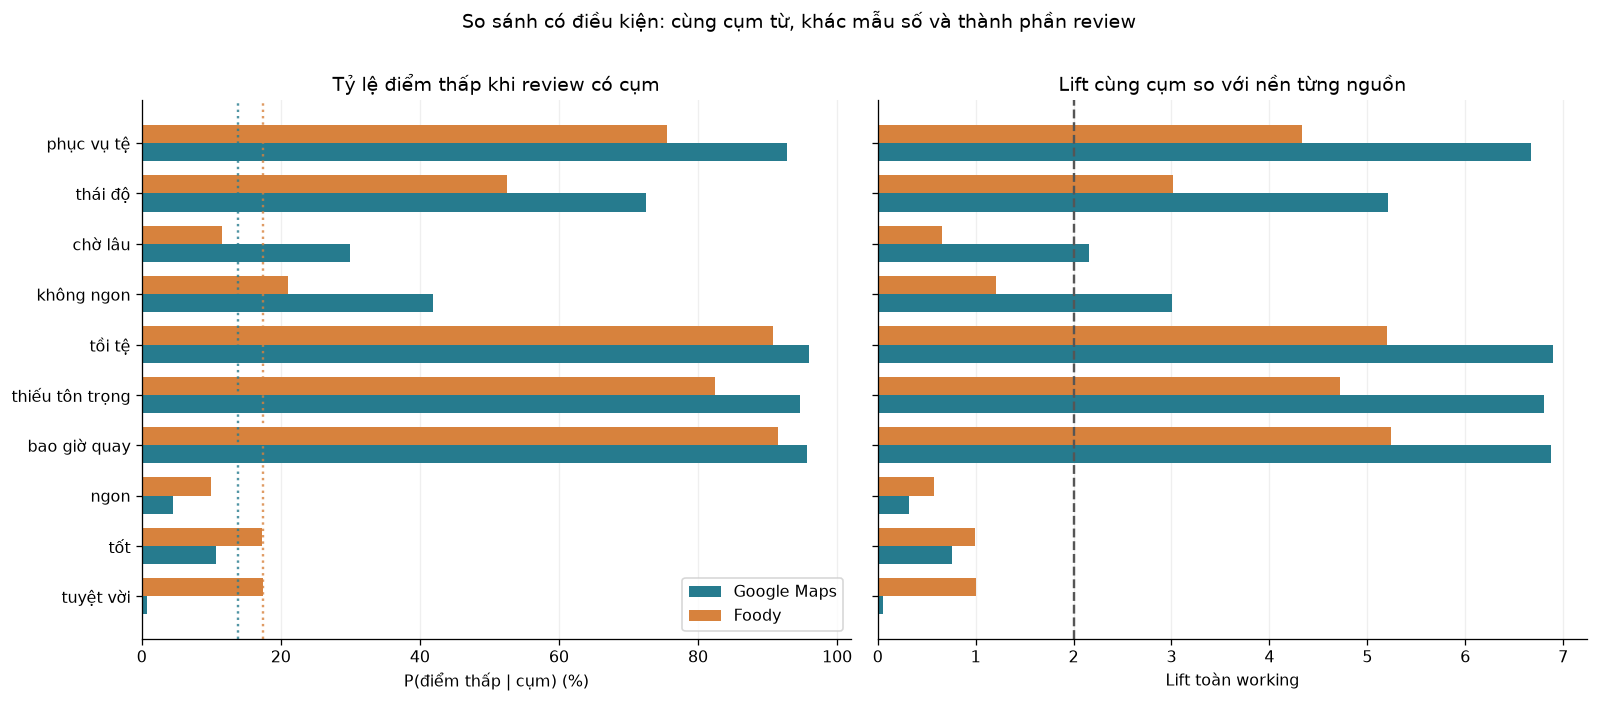

In [17]:
show_terms=list(reversed(paired_terms))
prob=paired_comparison.pivot(index='keyword',columns='source',values='p_low_pct').reindex(show_terms)
lifts=paired_comparison.pivot(index='keyword',columns='source',values='lift_all').reindex(show_terms)
fig,axes=plt.subplots(1,2,figsize=(14,6),sharey=True)
positions=np.arange(len(show_terms)); height=.36
for offset,(name,color) in zip([-.18,.18],[('Google Maps','#267b8e'),('Foody','#d7823d')]):
    axes[0].barh(positions+offset,prob[name],height=height,color=color,label=name)
    axes[1].barh(positions+offset,lifts[name],height=height,color=color,label=name)
axes[0].set_yticks(positions,show_terms)
axes[0].axvline(100*working.is_low.mean(),color='#267b8e',linestyle=':',alpha=.8)
axes[0].axvline(100*foody_working.is_low.mean(),color='#d7823d',linestyle=':',alpha=.8)
axes[0].set(title='Tỷ lệ điểm thấp khi review có cụm',xlabel='P(điểm thấp | cụm) (%)',xlim=(0,102))
axes[1].axvline(2,color='#555',linestyle='--')
axes[1].set(title='Lift cùng cụm so với nền từng nguồn',xlabel='Lift toàn working')
for ax in axes: ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
axes[0].legend(loc='lower right')
fig.suptitle('So sánh có điều kiện: cùng cụm từ, khác mẫu số và thành phần review',y=1.01)
plt.tight_layout(); plt.show()

### Cách đọc khác biệt từ hai biểu đồ

Ở cùng cụm phàn nàn trực tiếp, Maps có cả xác suất điểm thấp khi có cụm và lift cao hơn trong hai file đang xét. Nhưng “tốt” và “tuyệt vời” gần đường nền Foody, trong khi thấp hơn nền Maps. Điều này phù hợp với bảng exact-text và bảng paired trước đó: liên hệ text–rating khác giữa hai nguồn, nên một ngưỡng keyword dùng chung cần được hiệu chỉnh/kiểm tra lại theo nguồn.

**Vòng phản biện:** cột biểu đồ không phải tỷ lệ tất cả khách hàng gặp một vấn đề, và không thể kết luận nhà hàng trên Maps phục vụ kém hơn từ các cột cao hơn. Đường nền, mẫu số, thang điểm, thành phần địa điểm và quy trình lấy mẫu đều khác. Căn cứ để kết luận về độ ổn định là các bảng validation; biểu đồ này chỉ tổng hợp thống kê mô tả.

## 12. Kết luận đối chiếu Google Maps và Foody cho cùng câu hỏi

**Câu hỏi:** từ/cụm từ nào liên hệ với review điểm thấp và có thể lặp lại khi chia dữ liệu? **Quy tắc suy luận áp dụng:** quy nạp từ các phép đếm, kiểm chứng trên validation tách nhóm và đối chiếu ngữ cảnh. Kết luận là liên hệ trong hai mẫu quan sát, không suy ra nguyên nhân hoặc cảm xúc chuẩn chỉ từ rating.

**Căn cứ:** [Maps JSON](../data/raw/ggmap/gmap.json), [Foody JSON](../data/processed/18-10-2026.json), các output phần 2–11 trong notebook này; hướng phương pháp từ [notebook Foody mẫu](eda._present.ipynb). Foody bên dưới là kết quả **tính lại sau lọc trùng**, không lấy các output lưu không đồng nhất làm mốc.

| Chỉ tiêu sau quy trình tương ứng | Google Maps | Foody |
|---|---:|---:|
| Review gốc | 147.565 | 138.131 |
| Review dùng cho keyword | 130.884 | 132.640 |
| Định nghĩa nhóm thấp | 1–2/5 sao | 0 < rating ≤5/10 |
| Review thấp | 18.218 (13,92%) | 23.144 (17,45%) |
| Địa điểm trong working | 1.900 | 5.538 |
| Độ dài trung vị / P95 (token regex) | 23 / 132 | 70 / 195 |
| Review thuộc nhóm text lặp | 5,56% | 5,85% |
| N-gram ổn định qua 5 lần chia text | 4.452 | 1.834 |
| N-gram ổn định chung hai nguồn | 982 | 982 |

### Câu trả lời chung và những khác biệt có ý nghĩa

**1. Phần giao đáng tin hơn là lời phàn nàn trực tiếp về thái độ/phục vụ và ý định không quay lại.** “Phục vụ tệ”, “thái độ”, “tồi tệ”, “thiếu tôn trọng”, “bao giờ quay” đạt tiêu chí ổn định theo text ở cả hai nguồn, đồng thời đạt support/lift trong phép chia quán bổ sung. Chẳng hạn, “phục vụ tệ” có 246/265 review thấp ở Maps và 176/233 ở Foody; “bao giờ quay” có 630/658 và 812/888. Đọc mẫu cho thấy “bao giờ quay” thường nằm trong phát biểu không quay lại, nhưng bản thân mảnh 3-gram thiếu phần phủ định nên không dùng như một luật cảm xúc độc lập.

**2. Một số tín hiệu không chuyển nguyên vẹn giữa hai nguồn.** “Không ngon” có lift toàn tập 3,009 ở Maps, 1,209 ở Foody; “chờ lâu” là 2,157 và 0,659. Maps đạt tiêu chí text-split cho cả hai, nhưng “chờ lâu” chỉ đạt 1,976 khi đổi sang quán khác. Mẫu thực tế có cả câu “chưa khi nào mình phải chờ lâu” và review khen/chê nhiều mặt. Vì vậy cần đọc ngữ cảnh và kiểm tra theo nguồn; không kết luận rằng người dùng Foody ít bận tâm về chờ đợi hay chất lượng món ăn.

**3. Khác biệt nằm cả ở văn bản và liên hệ giữa điểm với văn bản.** Foody dài hơn khoảng 3 lần về trung vị và tạo khoảng 32,04 triệu lượt 1–3 gram, so với 15,20 triệu ở Maps. Foody còn có các text khen rất ngắn nhưng điểm thấp: đúng bằng “tốt” có 198/280 review thấp (70,71%), so với 9/407 ở Maps (2,21%). Đây là lý do cần audit rating/nguồn trước khi dùng điểm làm nhãn cảm xúc; chưa đủ căn cứ để xác định lỗi nằm ở người viết, cách chấm điểm hay xử lý dữ liệu.

**4. Maps có nhiều cụm ổn định hơn không đồng nghĩa chất lượng dữ liệu tốt hơn.** Baseline thấp hơn làm trần lift khác nhau (khoảng 7,18 so với 5,73); độ dài, số quán, chính sách lọc trùng và thành phần địa điểm cũng khác. Maps thiếu ngày đăng chính xác, 10,53% text rỗng ở nguồn và có mẫu chợ/lưu trú; Foody có nhiều quán hơn, còn chính sách trùng dùng thêm thời gian/thiết bị. Các đặc điểm này giới hạn cách so trực tiếp hai nền tảng.

### Vòng phản biện cuối: giả định, cách giải thích khác và hướng xác minh

Giả định `rating/scale ≤0,5` chỉ giúp thống nhất ngưỡng số học; chưa chứng minh 2/5 sao và 5/10 phản ánh cùng mức bất mãn. Khảo sát ≤3/5 mới kiểm tra ba cụm tiêu biểu, chưa kiểm chứng lại toàn bộ từ điển. Review điểm cao vẫn có lời chê, nên kết quả hiện trả lời câu hỏi về **điểm thấp**, chưa là kết quả phân loại cảm xúc/khía cạnh có ground truth.

Khác biệt có thể đồng thời đến từ cách lấy mẫu, địa bàn/loại địa điểm, ngôn ngữ, độ dài và quá trình xử lý điểm. Notebook chưa tách được mức đóng góp từng yếu tố. Việc không trùng exact text hoặc shop ID không loại hết câu gần giống, chuỗi thương hiệu hay khác biệt thu thập; một phép chia quán bổ sung và các lần chia dùng lại review cũng không phải kiểm định độc lập trên dữ liệu mới.

Để xác minh tiếp, ưu tiên truy vết các review Foody khen nhưng điểm thấp bằng review ID về rating gốc; gán nhãn thủ công cảm xúc/khía cạnh trên mẫu phân tầng của cả hai nguồn; rồi so các nhóm có địa bàn, loại địa điểm và độ dài tương đồng. Nếu đưa keyword vào mô hình, cần tập mới chưa được xem trong EDA, chia theo quán và kiểm tra chuyển nguồn. Có thể tái lập các con số hiện tại bằng `Restart Kernel → Run All`, giữ nguyên hai file nguồn/seed và đối chiếu SHA256, phiên bản thư viện đã in.